# Dashboard de Vendas e Gestão de Estoque

Problema de negócio: uma empresa comercial possui milhares de registros de vendas, mas tem dificuldade para identificar os produtos mais importantes, acompanhar o faturamento e planejar a reposição de mercadorias.

Solução: criar um painel interativo que transforme esses registros em informações para a tomada de decisões.

Indicadores a ser desenvolvidos:

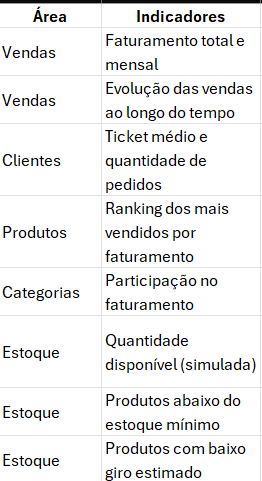

Ferramentas: Python/Pandas para tratamento dos dados, SQL para consultas e Power BI para modelagem, medidas DAX e visualização.

# Roteiro

#### Etapa 1 — Limpeza e preparação dos dados

- Importar o CSV no Python, identificar inconsistências, tratar datas, valores nulos e padronizar as colunas.


#### Etapa 2 — Modelagem de estoque

- Criar uma tabela simulada de estoque, definir mínimos e estruturar indicadores de reposição.
  

#### Etapa 3 — SQL e modelagem

- Criar tabelas de vendas, produtos, clientes e calendário. Construir consultas para responder perguntas de negócio.


#### Etapa 4 — Power BI

- Criar medidas DAX, gráficos, cartões de indicadores e filtros interativos.

# 1. Bibliotecas

In [237]:
import pandas as pd
import numpy as np
from pathlib import Path

# 2. Base de Dados

### Importando o arquivo CSV

In [240]:
df = pd.read_csv(
    "../dados/train.csv",
    sep=";",
    dtype={"Postal Code": "string"}
)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,9.575.775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368


# 3. Análise Exploratória

Observe a coluna Sales: existem valores como 261.96, mas também 9.575.775.

Esse é um dos problemas que será necessário investigar antes de calcular o faturamento.

## 3.1 Tamanho Dataframe

### Verificar o tamanho do DataFrame

In [245]:
df.shape

(9800, 18)

## 3.2 Informações sobre o Dataframe

### Verificar os tipos de dados

In [248]:
#Isso mostra quais colunas são numéricas, textuais ou de datas, além da quantidade de valores não nulos.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Row ID         9800 non-null   int64 
 1   Order ID       9800 non-null   object
 2   Order Date     9800 non-null   object
 3   Ship Date      9800 non-null   object
 4   Ship Mode      9800 non-null   object
 5   Customer ID    9800 non-null   object
 6   Customer Name  9800 non-null   object
 7   Segment        9800 non-null   object
 8   Country        9800 non-null   object
 9   City           9800 non-null   object
 10  State          9800 non-null   object
 11  Postal Code    9789 non-null   string
 12  Region         9800 non-null   object
 13  Product ID     9800 non-null   object
 14  Category       9800 non-null   object
 15  Sub-Category   9800 non-null   object
 16  Product Name   9800 non-null   object
 17  Sales          9794 non-null   object
dtypes: int64(1), object(16), str

### Identificar valores ausentes

In [250]:
#Identificar valores ausentes
df.isnull().sum().sort_values(ascending=False)

Postal Code      11
Sales             6
Order ID          0
Product Name      0
Sub-Category      0
Category          0
Product ID        0
Region            0
State             0
Row ID            0
Country           0
Segment           0
Customer Name     0
Customer ID       0
Ship Mode         0
Ship Date         0
Order Date        0
City              0
dtype: int64

### Verificar registros duplicados

In [252]:
#Esse comando identifica linhas completamente idênticas.
df.duplicated().sum()

0

## 3.3 Análise Coluna "Sales"

In [254]:
df["Sales"].describe()

count      9794
unique     5754
top       12.96
freq         55
Name: Sales, dtype: object

Existem 186 valores de Sales com mais de um ponto, como 9.575.775, e outros com três casas após um único ponto, como 22.368.

Não é possível simplesmente remover todos os pontos: isso poderia transformar 261.96 em 26196, distorcendo o faturamento.

Também não se deve assumir que 9.575.775 representa 9 milhões. É necessário investigar a convenção utilizada e, quando possível, comparar os registros com a fonte original antes de definir uma regra de conversão.

# 4. Tratamento de Dados

## 4.1 Alterando o Tipo da Variável Para as Colunas de Datas

Atualmente, o Pandas interpreta Order Date e Ship Date como texto (object).

Convertendo para datetime, é possível calcular vendas por mês, ano e dia da semana.

### Convertendo as colunas de datas

In [259]:
# Converter as colunas de datas
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d/%m/%Y",
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Conferir o resultado
df[["Order Date", "Ship Date"]].head()

,Order Date,Ship Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18


In [260]:
df[["Order Date", "Ship Date"]].isnull().sum()

Order Date    0
Ship Date     0
dtype: int64

## 4.2 Conversão da Coluna "Sales" para Unidade Monetária

Antes de converter os valores, foi verificado quantos pontos aparecem em cada registro.

### Investigando a coluna Sales

In [263]:
# Contar a quantidade de pontos em cada valor
contagem_pontos = (
    df["Sales"]
    .astype("string")
    .str.count(r"\.")
    .value_counts(dropna=False)
)

print(contagem_pontos)

Sales
1       9483
2        186
0        125
<NA>       6
Name: count, dtype: Int64


In [264]:
# Selecionar vendas com mais de um ponto
vendas_suspeitas = df[
    df["Sales"]
    .astype("string")
    .str.count(r"\.")
    .gt(1)
    .fillna(False)
]

vendas_suspeitas[
    ["Row ID", "Product Name", "Sales"]
].head(15)

,Row ID,Product Name,Sales
3,4,Bretford CR4500 Series Slim Rectangular Table,9.575.775
10,11,Chromcraft Rectangular Conference Tables,1.706.184
35,36,GE 30524EE4,1.097.544
38,39,"Atlantic Metals Mobile 3-Shelf Bookcases, Cust...",5.323.992
67,68,Hunt BOSTON Model 1606 High-Volume Electric Pe...,1.113.024
165,166,Lexmark MX611dhe Monochrome Laser Printer,8.159.952
232,233,Bretford Rectangular Conference Table Tops,6.206.145
262,263,Lexmark MX611dhe Monochrome Laser Printer,3.059.982
263,264,Xerox WorkCentre 6505DN Laser Multifunction Pr...,2.519.958
353,354,GBC DocuBind P400 Electric Binding System,4.355.168



Visualizando alguns valores que possuem mais de um ponto, ajuda a identificar o padrão de formatação.

Por que não converter imediatamente?

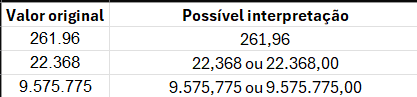

Se esses números forem interpretados incorretamente, o dashboard poderá apresentar faturamentos muito maiores do que os reais.

Por isso, é necessário estabelecer uma regra de conversão fundamentada nos dados.

### Investigando os valores ausentes

In [266]:
df[df["Sales"].isnull()]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
181,182,CA-2015-166191,2015-12-05,2015-12-09,Second Class,DK-13150,David Kendrick,Corporate,United States,Decatur,Illinois,62521,Central,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
430,431,US-2017-123750,2017-04-15,2017-04-21,Standard Class,RB-19795,Ross Baird,Home Office,United States,Gastonia,North Carolina,28052,South,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
431,432,US-2017-123750,2017-04-15,2017-04-21,Standard Class,RB-19795,Ross Baird,Home Office,United States,Gastonia,North Carolina,28052,South,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
1406,1407,US-2015-118486,2015-04-06,2015-04-08,First Class,SD-20485,Shirley Daniels,Home Office,United States,Philadelphia,Pennsylvania,19143,East,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
1969,1970,CA-2018-117485,2018-09-23,2018-09-29,Standard Class,BD-11320,Bill Donatelli,Consumer,United States,Tulsa,Oklahoma,74133,Central,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
1971,1972,CA-2018-140242,2018-05-06,2018-05-11,Standard Class,ML-17755,Max Ludwig,Home Office,United States,Chicago,Illinois,60623,Central,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN


Esses registros não serão excluidos automaticamente. Primeiro é preciso entender se eles devem ser descartados, recuperados ou mantidos com indicação de valor ausente.

Quanto aos 11 códigos postais ausentes, por enquanto, serão mantidos como nulos, já que não impedem a análise financeira.

### 4.2.1 Investigando o padrão de pontos na coluna "Sales"

Observando o comprimento dos grupos separados por pontos.

### Investigando os valores monetários

In [270]:
# Separar os valores em grupos
amostra = df.loc[
    df["Sales"].astype("string").str.count(r"\.").eq(2).fillna(False),
    "Sales"
]

for valor in amostra.head(15):
    print(valor, "->", valor.split("."))

9.575.775 -> ['9', '575', '775']
1.706.184 -> ['1', '706', '184']
1.097.544 -> ['1', '097', '544']
5.323.992 -> ['5', '323', '992']
1.113.024 -> ['1', '113', '024']
8.159.952 -> ['8', '159', '952']
6.206.145 -> ['6', '206', '145']
3.059.982 -> ['3', '059', '982']
2.519.958 -> ['2', '519', '958']
4.355.168 -> ['4', '355', '168']
1.023.936 -> ['1', '023', '936']
1.488.424 -> ['1', '488', '424']
3.754.575 -> ['3', '754', '575']
23.962.656 -> ['23', '962', '656']
1.199.976 -> ['1', '199', '976']


Isso confirma o padrão textual, mas não a posição correta do separador decimal.

Testando a hipótese de que os valores foram alterados durante a exportação.

Por exemplo, o registro Row ID = 4, referente à mesa Bretford CR4500, possui no conjunto de dados Superstore conhecido um valor de venda de aproximadamente 957,5775.

Portanto, o texto 9.575.775 é compatível com esse número se removermos os pontos e dividirmos por 10.000.

Mas é preciso verificar se essa mesma regra funciona para os demais registros, especialmente aqueles com apenas um ponto.

### Comparar diferentes formatos

In [272]:

# Separar exemplos por quantidade de pontos
sales_texto = df["Sales"].astype("string")
qtd_pontos = sales_texto.str.count(r"\.")

for quantidade in [0, 1, 2]:
    print(f"\nValores com {quantidade} ponto(s):")

    exemplos = df.loc[
        qtd_pontos.eq(quantidade).fillna(False),
        ["Row ID", "Sales"]
    ]

    print(exemplos.head(15).to_string(index=False))



Valores com 0 ponto(s):
 Row ID Sales
     48    45
     60    30
    185    29
    216  1188
    321   360
    562    13
    651   316
    772   207
    783    24
    827    35
    927   252
   1242    22
   1455  3040
   1485   177
   1508   396

Valores com 1 ponto(s):
 Row ID   Sales
      1  261.96
      2  731.94
      3   14.62
      5  22.368
      6   48.86
      7    7.28
      8 907.152
      9  18.504
     10   114.9
     12 911.424
     13  15.552
     14 407.976
     15   68.81
     16   2.544
     17  665.88

Valores com 2 ponto(s):
 Row ID      Sales
      4  9.575.775
     11  1.706.184
     36  1.097.544
     39  5.323.992
     68  1.113.024
    166  8.159.952
    233  6.206.145
    263  3.059.982
    264  2.519.958
    354  4.355.168
    374  1.023.936
    378  1.488.424
    385  3.754.575
    400 23.962.656
    407  1.199.976


Os registros apresentam três formatos diferentes:

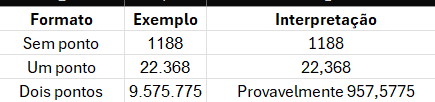

O problema está nos 186 registros com dois pontos.

Comparando com valores conhecidos da base Superstore, há indícios de que esses registros sofreram uma alteração de formatação durante a exportação.

Por exemplo:

9.575.775 → 957.5775

Para esse padrão específico, é possível remover os pontos e dividir por 10.000. 

### Criando uma função de tratamento

In [274]:
#Função de tratamento da coluna "Sales"

def corrigir_sales(valor):
    # Preservar valores ausentes
    if pd.isna(valor):
        return np.nan

    valor = str(valor).strip()

    # Contar os pontos
    quantidade_pontos = valor.count(".")

    if quantidade_pontos == 2:
        # Exemplo: 9.575.775 -> 957.5775
        return float(valor.replace(".", "")) / 10000

    elif quantidade_pontos <= 1:
        # Exemplo: 261.96 -> 261.96
        return float(valor)

    else:
        # Formatos inesperados
        return np.nan

### Aplicando a função ao DataFrame

In [276]:
#Preservando a coluna original e criando outra chamada Sales_Tratado.

df["Sales_Tratado"] = df["Sales"].apply(corrigir_sales)

df[
    ["Row ID", "Sales", "Sales_Tratado"]
].head(15)

,Row ID,Sales,Sales_Tratado
0,1,261.96,261.9600
1,2,731.94,731.9400
2,3,14.62,14.6200
3,4,9.575.775,957.5775
4,5,22.368,22.3680
5,6,48.86,48.8600
6,7,7.28,7.2800
7,8,907.152,907.1520
8,9,18.504,18.5040
9,10,114.9,114.9000


Observe que 1.706.184 se transforma em 170.6184 com a regra adotada. Essa é uma hipótese de correção, não uma confirmação de que todos os valores estejam corretos.

### Validando o tratamento

In [278]:
# Conferir o tipo da nova coluna
print(df["Sales_Tratado"].dtype)

# Estatísticas descritivas
print(df["Sales_Tratado"].describe())

# Verificar valores ausentes
print(df["Sales_Tratado"].isnull().sum())

# Verificar os maiores valores
print(
    df.nlargest(10, "Sales_Tratado")[
        ["Row ID", "Product Name", "Sales", "Sales_Tratado"]
    ]
)

#A análise dos maiores valores é especialmente útil para identificar possíveis erros que ainda estejam presentes.

float64
count     9794.000000
mean       202.328558
std        557.474909
min          0.444000
25%         17.242000
50%         54.376000
75%        199.750000
max      22638.480000
Name: Sales_Tratado, dtype: float64
6
      Row ID                                       Product Name     Sales  \
2697    2698  Cisco TelePresence System EX90 Videoconferenci...  22638.48   
6826    6827              Canon imageCLASS 2200 Advanced Copier  17499.95   
8153    8154              Canon imageCLASS 2200 Advanced Copier  13999.96   
4190    4191              Canon imageCLASS 2200 Advanced Copier  10499.97   
9039    9040   GBC Ibimaster 500 Manual ProClick Binding System   9892.74   
4098    4099               Ibico EPK-21 Electric Binding System   9449.95   
4277    4278   3D Systems Cube Printer, 2nd Generation, Magenta   9099.93   
8488    8489  HP Designjet T520 Inkjet Large Format Printer ...   8749.95   
2505    2506        High Speed Automatic Electric Letter Opener   8187.65   
683     

É possivel tirar três conclusões:

1. A média é muito maior que a mediana.

    - Isso indica que existem vendas de valores elevados puxando a média para cima. É uma característica comum em distribuições assimétricas à direita.

2. O desvio padrão é elevado.

    - Há grande dispersão entre os valores das vendas, o que é plausível para uma loja que comercializa desde pequenos materiais de escritório até equipamentos caros.

3. Os maiores valores parecem plausíveis.

    - Por exemplo, um sistema de videoconferência Cisco de 22.638,48 e uma copiadora Canon de 17.499,95 são compatíveis com produtos de alto valor.

Entretanto, existe uma ressalva: os dez maiores registros apresentados já tinham valores com apenas um ponto. Portanto, essa verificação ainda não comprova que corrigimos adequadamente os 186 registros com dois pontos.

### Validando especificamente os valores corrigidos

In [280]:
# Selecionar os registros que foram corrigidos
corrigidos = df[
    df["Sales"]
    .astype("string")
    .str.count(r"\.")
    .eq(2)
    .fillna(False)
].copy()

# Verificar as estatísticas desses registros
print(corrigidos["Sales_Tratado"].describe())

# Mostrar os maiores valores corrigidos
print(
    corrigidos.nlargest(10, "Sales_Tratado")[
        ["Row ID", "Sales", "Sales_Tratado"]
    ].to_string(index=False)
)

count     186.000000
mean      259.398368
std       264.869802
min       100.158400
25%       120.319400
50%       165.318600
75%       288.528000
max      2396.265600
Name: Sales_Tratado, dtype: float64
 Row ID      Sales  Sales_Tratado
    400 23.962.656      2396.2656
   5056 13.523.976      1352.3976
   8782 12.279.984      1227.9984
   2624 11.199.968      1119.9968
      4  9.575.775       957.5775
   2404  9.566.648       956.6648
   4267  9.566.648       956.6648
   4496  9.179.235       917.9235
   6426  8.399.976       839.9976
    166  8.159.952       815.9952


Por que fazer isso?

Porque um erro de formatação pode não aparecer entre os dez maiores valores, mas ainda assim alterar significativamente o faturamento total.

Além disso, existe uma possível inconsistência que é necessário investigar: 1.706.184 pode corresponder a 1706.184, e não a 170.6184.

Ou seja, a regra atual de dividir por 10.000 talvez não funcione para todos os registros. É preciso comparar os valores com a fonte original ou estabelecer uma regra confiável antes de considerá-los definitivos.

## 4.3 Tratamento de Dados Faltantes na Coluna "Sales"

### Investigando os seis registros sem vendas

In [284]:
# Visualizar registros sem valor de venda

df.loc[
    df["Sales_Tratado"].isna(),
    [
        "Row ID",
        "Order ID",
        "Order Date",
        "Product ID",
        "Product Name",
        "Sales"
    ]
]

,Row ID,Order ID,Order Date,Product ID,Product Name,Sales
181,182,CA-2015-166191,2015-12-05,TEC-AC-10004659,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
430,431,US-2017-123750,2017-04-15,TEC-AC-10004659,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
431,432,US-2017-123750,2017-04-15,TEC-AC-10004659,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
1406,1407,US-2015-118486,2015-04-06,TEC-AC-10004659,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
1969,1970,CA-2018-117485,2018-09-23,TEC-AC-10004659,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN
1971,1972,CA-2018-140242,2018-05-06,TEC-AC-10004659,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,NaN


Esses registros não devem receber valor zero automaticamente, porque venda desconhecida é diferente de venda igual a zero.

Duas informações importantes, retiradas dessa análise:

    - Os 186 registros com dois pontos seguem um padrão que podemos investigar para confirmar a conversão.
    - Os seis valores ausentes pertencem ao mesmo produto, o que merece atenção especial.

Validando os 186 valores corrigidos

Os valores que aparecem com dois pontos podem ter sido produzidos por diferentes processos de formatação. Por isso, a regra não pode ser considerada definitivamente validada apenas porque as estatísticas parecem razoáveis.

Investigando os seis valores ausentes

Todos pertencem ao produto:

Imation Secure+ Hardware Encrypted USB 2.0 Flash Drive

E possuem o mesmo Product ID:

TEC-AC-10004659

Isso significa que é possível investigar se existem outras vendas desse mesmo produto com valores preenchidos.

Se existirem registros válidos do mesmo produto, é possível analisar os valores praticados e verificar se é possível recuperar as informações ausentes.

Mas existe um detalhe: essa base não possui quantidade vendida. Portanto, mesmo que seja encontrado uma venda de R$ 100 para o mesmo produto, não há a possibilidade de assumir que outra venda também teria esse valor.

Existem três possibilidades:

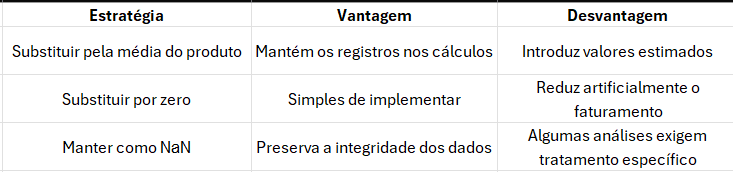

Caso não for possível recuperar os valores ausentes, NaN será mantido.

Isso é mais adequado para um dashboard financeiro, porque evita inventar faturamento.

In [286]:
# Identificar todas as vendas do produto
produto = df[
    df["Product ID"] == "TEC-AC-10004659"
]

# Verificar quantos registros existem
print("Total de registros:", len(produto))

# Quantos possuem vendas preenchidas?
print(
    "Registros com vendas:",
    produto["Sales_Tratado"].notna().sum()
)

# Visualizar os registros
print(
    produto[
        ["Row ID", "Order Date", "Sales", "Sales_Tratado"]
    ].to_string(index=False)
)

Total de registros: 6
Registros com vendas: 0
 Row ID Order Date Sales  Sales_Tratado
    182 2015-12-05   NaN            NaN
    431 2017-04-15   NaN            NaN
    432 2017-04-15   NaN            NaN
   1407 2015-04-06   NaN            NaN
   1970 2018-09-23   NaN            NaN
   1972 2018-05-06   NaN            NaN


Confirmandos que todos os seis registros desse produto estão sem valor de venda.

Isso significa que não há informações suficientes para recuperar o faturamento desse produto a partir da própria base.

No dashboard, os seis registros continuarão disponíveis para auditoria, mas não contribuirão com valores inventados para o faturamento.

### Criando uma coluna de qualidade dos dados

In [288]:
df["Status_Venda"] = np.where(
    df["Sales_Tratado"].notna(),
    "Valor informado",
    "Valor ausente"
)

# Conferir a distribuição
df["Status_Venda"].value_counts()

Status_Venda
Valor informado    9794
Valor ausente         6
Name: count, dtype: int64

## 4.4 Conferência de IDs Únicos 

### Verificando a integridade dos identificadores

In [291]:
print("Registros totais:", len(df))

print(
    "Row IDs únicos:",
    df["Row ID"].nunique()
)

print(
    "Row IDs duplicados:",
    df["Row ID"].duplicated().sum()
)

# Isso é diferente de verificar linhas completamente duplicadas. Aqui está sendo avaliado a unicidade de um identificador específico.

Registros totais: 9800
Row IDs únicos: 9800
Row IDs duplicados: 0


Isso indica que Row ID pode ser utilizado como identificador único das linhas da tabela de vendas.

## 4.5 Dia do Pedido e Dia de Envio

### Validando as datas de entrega

Temos duas colunas de datas:

    - Order Date: data em que o pedido foi realizado.
    - Ship Date: data em que o pedido foi enviado.

Será verificado se existem pedidos enviados antes de serem realizados, o que indicaria uma inconsistência.

Análise dos prazos de envio

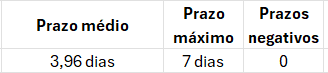



In [296]:
# Calcular o intervalo entre pedido e envio
df["Dias_Envio"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Estatísticas do prazo de envio
print(df["Dias_Envio"].describe())

# Verificar prazos negativos
print(
    "Envios com prazo negativo:",
    (df["Dias_Envio"] < 0).sum()
)

count    9800.000000
mean        3.961122
std         1.749614
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Dias_Envio, dtype: float64
Envios com prazo negativo: 0


Resumo dos prazos de envio

Valores em dias, calculados a partir das estatísticas do DataFrame

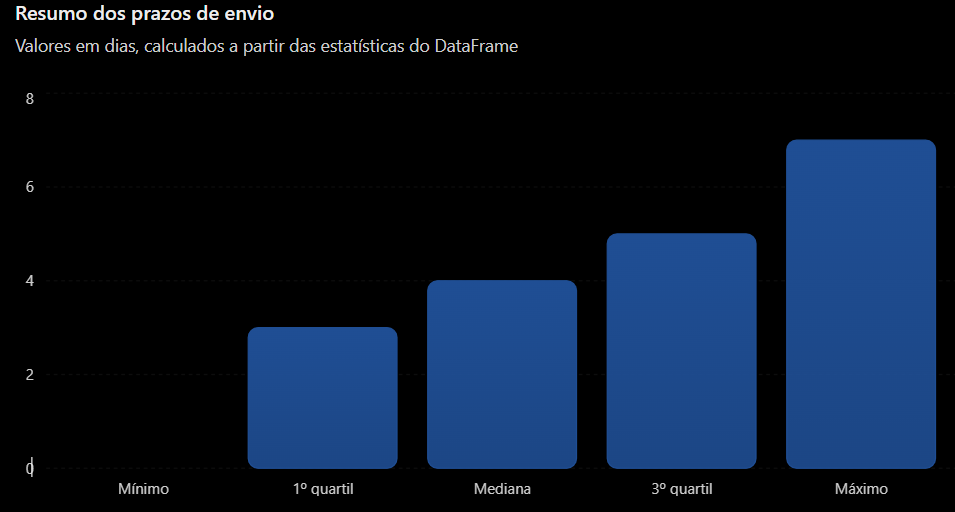

Esses resultados são interessantes para o futuro dashboard. Pode-se criar indicadores como prazo médio de envio e comparar o desempenho logístico por modalidade de entrega.

Uma ressalva: o prazo de envio não representa necessariamente o prazo de entrega ao cliente, pois Ship Date registra a data de expedição.

## 4.6 Auditoria da Coluna "Sales"

Ainda há uma pendência: confirmar a regra usada para os 186 registros com dois pontos.

Foi identificado que 9.575.775 provavelmente representa 957.5775, mas não é possível assumir que todos os registros seguem necessariamente a mesma regra.

Para tornar o tratamento mais confiável, será comparado alguns valores conhecidos da base Superstore.

In [300]:
# Selecionar registros para auditoria
ids_auditoria = [4, 11, 36, 39, 400]

auditoria = df.loc[
    df["Row ID"].isin(ids_auditoria),
    ["Row ID", "Product Name", "Sales", "Sales_Tratado"]
]

print(auditoria.to_string(index=False))

 Row ID                                                  Product Name      Sales  Sales_Tratado
      4                 Bretford CR4500 Series Slim Rectangular Table  9.575.775       957.5775
     11                      Chromcraft Rectangular Conference Tables  1.706.184       170.6184
     36                                                   GE 30524EE4  1.097.544       109.7544
     39       Atlantic Metals Mobile 3-Shelf Bookcases, Custom Colors  5.323.992       532.3992
    400 Riverside Palais Royal Lawyers Bookcase, Royale Cherry Finish 23.962.656      2396.2656


### Preparando uma cópia da base tratada

In [302]:
# Criar uma cópia da base
df_limpo = df.copy()

# Renomear colunas para facilitar o trabalho
df_limpo = df_limpo.rename(columns={
    "Row ID": "ID_Linha",
    "Order ID": "ID_Pedido",
    "Order Date": "Data_Pedido",
    "Ship Date": "Data_Envio",
    "Ship Mode": "Modo_Envio",
    "Customer ID": "ID_Cliente",
    "Customer Name": "Nome_Cliente",
    "Product ID": "ID_Produto",
    "Product Name": "Nome_Produto",
    "Category": "Categoria",
    "Sub-Category": "Subcategoria",
    "Sales_Tratado": "Valor_Venda"
})

# Verificar as colunas
print(df_limpo.columns.tolist())

['ID_Linha', 'ID_Pedido', 'Data_Pedido', 'Data_Envio', 'Modo_Envio', 'ID_Cliente', 'Nome_Cliente', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'ID_Produto', 'Categoria', 'Subcategoria', 'Nome_Produto', 'Sales', 'Valor_Venda', 'Status_Venda', 'Dias_Envio']


### Verificando o faturamento provisório

In [304]:
faturamento_provisorio = df_limpo["Valor_Venda"].sum()

print(
    f"Faturamento provisório: "
    f"{faturamento_provisorio:,.2f}"
)

Faturamento provisório: 1,981,605.90


Esse número ainda não deve ser apresentado como faturamento definitivo, porque é preciso concluir a validação da conversão.

Também vale lembrar que cada linha representa um item de pedido, e não necessariamente um pedido completo. Portanto, a média de Valor_Venda não deve ser chamada de ticket médio. O ticket médio será calculado posteriormente dividindo o faturamento pela quantidade de pedidos únicos.

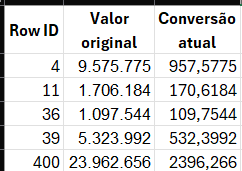

O registro 4 é compatível com um valor conhecido da base Superstore. Entretanto, não há confirmação independente para os demais.

O problema da função é que ela divide todos os valores com dois pontos por 10.000. Isso pressupõe que todos possuam exatamente quatro casas decimais, o que não necessariamente é verdade.

Por exemplo, 1.706.184 poderia representar 1706.184 ou 170.6184, dependendo da transformação aplicada na origem.

### Identificando a origem do problema

In [306]:
# Criar uma tabela apenas com os registros suspeitos
auditoria_sales = df.loc[
    df["Sales"]
    .astype("string")
    .str.count(r"\.")
    .eq(2)
    .fillna(False),
    ["Row ID", "Product ID", "Product Name",
     "Sales", "Sales_Tratado"]
].copy()

# Criar uma coluna para indicar revisão
auditoria_sales["Status_Revisao"] = "Pendente"

# Conferir a quantidade
print("Registros para auditoria:", len(auditoria_sales))

auditoria_sales.head()

Registros para auditoria: 186


,Row ID,Product ID,Product Name,Sales,Sales_Tratado,Status_Revisao
3,4,FUR-TA-10000577,Bretford CR4500 Series Slim Rectangular Table,9.575.775,957.5775,Pendente
10,11,FUR-TA-10001539,Chromcraft Rectangular Conference Tables,1.706.184,170.6184,Pendente
35,36,TEC-PH-10004977,GE 30524EE4,1.097.544,109.7544,Pendente
38,39,FUR-BO-10002545,"Atlantic Metals Mobile 3-Shelf Bookcases, Cust...",5.323.992,532.3992,Pendente
67,68,OFF-AR-10002671,Hunt BOSTON Model 1606 High-Volume Electric Pe...,1.113.024,111.3024,Pendente


### Preparando um arquivo de auditoria

In [308]:
pasta_saida = Path("../dados_tratados")
pasta_saida.mkdir(parents=True, exist_ok=True)

auditoria_sales.to_csv(
    pasta_saida / "auditoria_sales.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

print("Arquivo de auditoria criado!")

Arquivo de auditoria criado!


## 4.7 Comparação com Base Externa Equivalente

A estratégia final para a resolução dos valores faltantes e correção valores monetarios será:

    1. Obter uma versão de referência do Superstore.
    
    2. Comparar os registros utilizando Row ID, Order ID e Product ID.
    
    3. Corrigir os valores monetários quando houver correspondência confiável.
    
    4. Verificar se o faturamento mudou.
    
    5. Exportar a base tratada para o Power BI.

### Carregar Base SuperStore Externa do Github

In [311]:
df_referencia = pd.read_csv("../dados/train_referencia.csv",
    sep=",",
    dtype={"Postal Code": "string"})

print(df_referencia.shape)
print(df_referencia.columns.tolist())

df_referencia.head()

(9800, 18)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


Será utilizado três identificadores para evitar correspondências incorretas.

Será analisado lado a lado:

- O valor original da base original do Kaggle, utilizada desde o principio.
  
- O valor convertido pela função.
  
- O valor encontrado na base de referência.

### Comparar os registros

In [313]:
chaves = ["Row ID", "Order ID", "Product ID"]

# Confirmar que a referência não tem IDs duplicados
assert not df_referencia["Row ID"].duplicated().any()

comparacao = df.merge(
    df_referencia[
        chaves + ["Sales"]
    ].rename(columns={
        "Sales": "Sales_Referencia"
    }),
    on=chaves,
    how="left",
    validate="one_to_one",
    indicator=True
)

print(comparacao["_merge"].value_counts())

_merge
both          9800
left_only        0
right_only       0
Name: count, dtype: int64


### Verificar os cinco registros que auditados

In [315]:
ids = [4, 11, 36, 39, 400]

comparacao.loc[
    comparacao["Row ID"].isin(ids),
    [
        "Row ID",
        "Sales",
        "Sales_Tratado",
        "Sales_Referencia"
    ]
]

,Row ID,Sales,Sales_Tratado,Sales_Referencia
3,4,9.575.775,957.5775,957.5775
10,11,1.706.184,170.6184,1706.1840
35,36,1.097.544,109.7544,1097.5440
38,39,5.323.992,532.3992,532.3992
399,400,23.962.656,2396.2656,2396.2656


### Medir quantos registros estão corretos

In [317]:
# Converter os valores de referência para número
comparacao["Sales_Referencia"] = pd.to_numeric(
    comparacao["Sales_Referencia"],
    errors="coerce"
)

# Comparar apenas registros com ambos os valores disponíveis
validos = (
    comparacao["Sales_Tratado"].notna()
    & comparacao["Sales_Referencia"].notna()
)

comparacao["Valores_Iguais"] = False

comparacao.loc[validos, "Valores_Iguais"] = np.isclose(
    comparacao.loc[validos, "Sales_Tratado"],
    comparacao.loc[validos, "Sales_Referencia"],
    rtol=0,
    atol=0.00001
)

print("Registros comparáveis:", validos.sum())

print(
    "Valores iguais:",
    comparacao.loc[validos, "Valores_Iguais"].sum()
)

print(
    "Valores diferentes:",
    (~comparacao.loc[validos, "Valores_Iguais"]).sum()
)

Registros comparáveis: 9794
Valores iguais: 9636
Valores diferentes: 158


Analisando os resultados

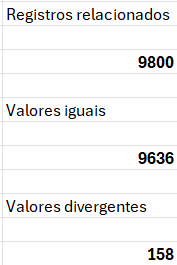

A comparação confirmou que nossa regra anterior não era adequada para todos os registros.

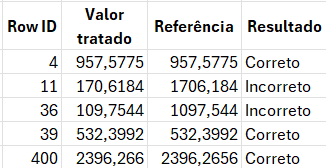

Isso mostra por que não devemos confiar somente em estatísticas descritivas para validar dados.

### Corrigindo os valores com a referência

In [319]:
# Criar coluna definitiva usando a referência
comparacao["Valor_Venda"] = comparacao["Sales_Referencia"]

# Identificar a origem do valor
comparacao["Origem_Valor"] = np.where(
    comparacao["Valor_Venda"].notna(),
    "Base de referência",
    "Valor ausente"
)

# Verificar os resultados
print(comparacao["Origem_Valor"].value_counts())

print(
    comparacao["Valor_Venda"].describe()
)

Origem_Valor
Base de referência    9800
Name: count, dtype: int64
count     9800.000000
mean       230.769059
std        626.651875
min          0.444000
25%         17.248000
50%         54.490000
75%        210.605000
max      22638.480000
Name: Valor_Venda, dtype: float64


Por que usar a referência?

Porque é possível relacionar todos os registros utilizando três identificadores. Isso reduz bastante o risco de atribuir uma venda ao produto ou pedido errado.

Entretanto, é importante documentar que os valores foram recuperados de uma versão externa do Superstore. A correspondência dos identificadores não garante, sozinha, que todos os demais campos sejam idênticos.

### Calculando o faturamento definitivo

Esse cálculo vai mostrar o impacto financeiro dos erros de formatação.

In [321]:
faturamento_anterior = comparacao["Sales_Tratado"].sum()

faturamento_corrigido = comparacao["Valor_Venda"].sum()

diferenca = faturamento_corrigido - faturamento_anterior

print(f"Faturamento anterior: {faturamento_anterior:,.2f}")
print(f"Faturamento corrigido: {faturamento_corrigido:,.2f}")
print(f"Diferença: {diferenca:,.2f}")

Faturamento anterior: 1,981,605.90
Faturamento corrigido: 2,261,536.78
Diferença: 279,930.89


### Verificando os valores ausentes novamente

In [323]:
print(
    "Valores ausentes na referência:",
    comparacao["Valor_Venda"].isna().sum()
)

print(
    comparacao.loc[
        comparacao["Valor_Venda"].isna(),
        ["Row ID", "Product ID", "Product Name"]
    ].to_string(index=False)
)

Valores ausentes na referência: 0
Empty DataFrame
Columns: [Row ID, Product ID, Product Name]
Index: []


Resultado da limpeza dos dados

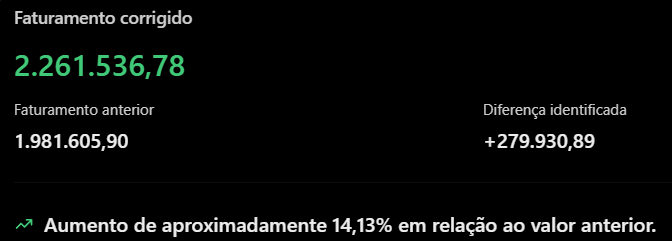

Isso demonstra como uma transformação incorreta dos dados pode comprometer os indicadores financeiros.

Além disso, os valores dos seis registros originalmente ausentes foram recuperados, utilizando a base de referência.

Importante: como a referência externa apresentou correspondência para todos os 9.800 registros, é possível utilizá-la como fonte dos valores corrigidos neste projeto.

## 4.8 Definição do Dataframe Final

### Criando a versão final do DataFrame

In [327]:
# Selecionar as colunas necessárias
colunas_finais = [
    "Row ID",
    "Order ID",
    "Order Date",
    "Ship Date",
    "Ship Mode",
    "Customer ID",
    "Customer Name",
    "Segment",
    "Country",
    "City",
    "State",
    "Postal Code",
    "Region",
    "Product ID",
    "Category",
    "Sub-Category",
    "Product Name",
    "Valor_Venda",
    "Dias_Envio",
    "Origem_Valor"
]

df_final = comparacao[colunas_finais].copy()

# Renomear colunas
df_final = df_final.rename(columns={
    "Row ID": "ID_Linha",
    "Order ID": "ID_Pedido",
    "Order Date": "Data_Pedido",
    "Ship Date": "Data_Envio",
    "Ship Mode": "Modo_Envio",
    "Customer ID": "ID_Cliente",
    "Customer Name": "Nome_Cliente",
    "Postal Code": "Codigo_Postal",
    "Product ID": "ID_Produto",
    "Category": "Categoria",
    "Sub-Category": "Subcategoria",
    "Product Name": "Nome_Produto",
    "Country": "Pais",
    "City": "Cidade",
    "State": "Estado",
    "Region": "Regiao",
    "Segment": "Segmento"
})

df_final.head()

,ID_Linha,ID_Pedido,Data_Pedido,Data_Envio,Modo_Envio,ID_Cliente,Nome_Cliente,Segmento,Pais,Cidade,Estado,Codigo_Postal,Regiao,ID_Produto,Categoria,Subcategoria,Nome_Produto,Valor_Venda,Dias_Envio,Origem_Valor
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,3,Base de referência
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,Base de referência
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,4,Base de referência
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,7,Base de referência
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,7,Base de referência


## 4.9 Validação da Integridade do Dataframe

### Validando a tabela final

In [330]:
assert len(df_final) == 9800

assert df_final["ID_Linha"].is_unique

assert df_final["Valor_Venda"].notna().all()

assert (df_final["Valor_Venda"] >= 0).all()

assert (df_final["Dias_Envio"] >= 0).all()

assert df_final["Data_Pedido"].notna().all()

assert df_final["Data_Envio"].notna().all()

print("Todas as validações foram aprovadas!")

Todas as validações foram aprovadas!


### Exportando o CSV tratado

In [332]:
# Definir a pasta de saída
pasta_saida = Path("../dados_tratados")

# Criar a pasta, caso não exista
pasta_saida.mkdir(parents=True, exist_ok=True)

# Exportar a base
df_final.to_csv(
    pasta_saida / "vendas_tratadas.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig",
    date_format="%Y-%m-%d",
    float_format="%.4f"
)

print("Arquivo vendas_tratadas.csv criado!")

Arquivo vendas_tratadas.csv criado!


Foi escolhido quatro casas decimais para preservar a precisão dos valores originais. O arredondamento para duas casas, quando necessário, poderá ser aplicado nas visualizações financeiras.

### Conferindo o arquivo exportado

In [334]:
df_teste = pd.read_csv(
    "../dados_tratados/vendas_tratadas.csv",
    sep=";",
    dtype={"Codigo_Postal": "string"}
)

print("Dimensões:", df_teste.shape)

print(
    "Faturamento:",
    round(df_teste["Valor_Venda"].sum(), 2)
)

print(
    "Valores ausentes em vendas:",
    df_teste["Valor_Venda"].isna().sum()
)

Dimensões: (9800, 20)
Faturamento: 2261536.78
Valores ausentes em vendas: 0


# 5. Modelagem dimensional dos dados

Modelo estrela (Star Schema)

O que é um modelo estrela?
É uma estrutura muito utilizada em projetos de Business Intelligence.

Ela separa os dados em dois tipos de tabelas:

- Tabela fato: contém os acontecimentos que queremos analisar, como vendas e valores financeiros.
  
- Tabelas dimensão: contêm informações utilizadas para filtrar, agrupar e contextualizar esses acontecimentos, como produtos, clientes e datas.

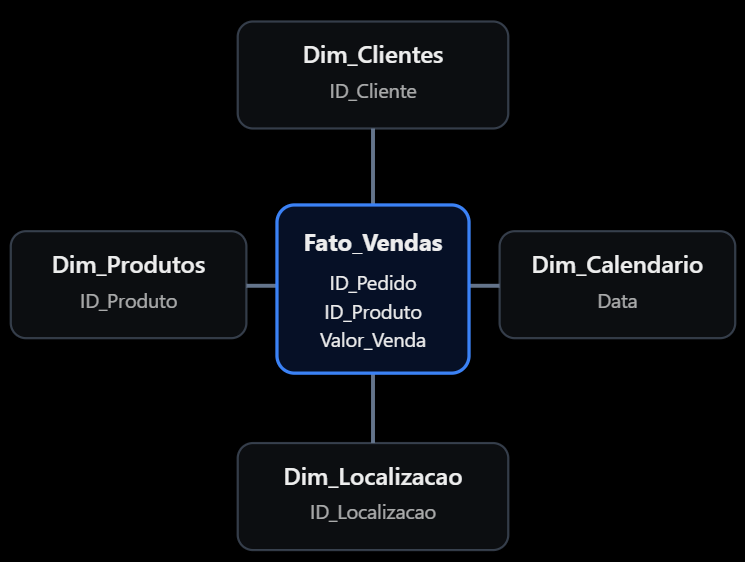

## 5.1 Dimensionamento Tabela Produtos

In [338]:
# Selecionar as colunas dos produtos
dim_produtos = df_final[
    [
        "ID_Produto",
        "Nome_Produto",
        "Categoria",
        "Subcategoria"
    ]
].copy()

# Verificar a quantidade de registros
print("Registros:", len(dim_produtos))

# Verificar a quantidade de produtos únicos
print(
    "Produtos únicos:",
    dim_produtos["ID_Produto"].nunique()
)

Registros: 9800
Produtos únicos: 1861


Investigar duplicações antes de criar a dimensão

É necessário verificar se cada ID_Produto está associado a um único nome, categoria e subcategoria.

Por que fazer isso?

Imagine que um mesmo ID_Produto apareça com dois nomes diferentes. Se duplicações forem removidas apenas pelo identificador, há a possibilidade de se perder informações ou escolher um cadastro arbitrariamente.

Em um modelo estrela, a chave da dimensão precisa identificar uma única linha. Portanto, será verificado essa integridade antes de construir a tabela definitiva.

A seguir as tabelas que serão feitas:

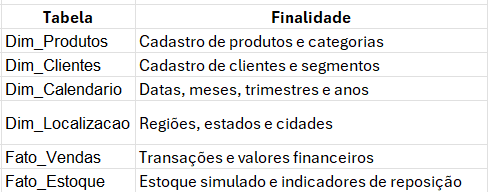

### Investigar duplicações antes de criar a dimensão

In [341]:
# Verificar produtos com mais de um conjunto
# de atributos cadastrais
inconsistencias = (
    dim_produtos
    .drop_duplicates()
    .groupby("ID_Produto")
    .size()
)

inconsistencias = inconsistencias[
    inconsistencias > 1
]

print(
    "Produtos com cadastros divergentes:",
    len(inconsistencias)
)

print(inconsistencias.head(10))

Produtos com cadastros divergentes: 32
ID_Produto
FUR-BO-10002213    2
FUR-CH-10001146    2
FUR-FU-10001473    2
FUR-FU-10004017    2
FUR-FU-10004091    2
FUR-FU-10004270    2
FUR-FU-10004848    2
FUR-FU-10004864    2
OFF-AP-10000576    2
OFF-AR-10001149    2
dtype: int64


32 códigos de produtos estão associados a mais de um conjunto de informações cadastrais.

Imagine uma situação hipotética:

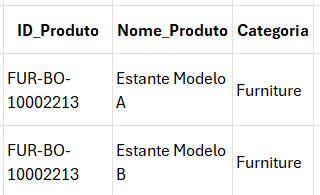

Se for utilizado apenas ID_Produto como chave, não conseguiremos distinguir os dois produtos.

Isso pode gerar relacionamentos muitos-para-muitos no Power BI e prejudicar nossos indicadores.

### Identificando os produtos com inconsistências

In [343]:
# Selecionar os produtos com cadastros divergentes
produtos_divergentes = dim_produtos[
    dim_produtos["ID_Produto"].isin(
        inconsistencias.index
    )
].drop_duplicates()

# Organizar por código
produtos_divergentes = produtos_divergentes.sort_values(
    ["ID_Produto", "Nome_Produto"]
)

# Visualizar os primeiros registros
produtos_divergentes.head(20)

,ID_Produto,Nome_Produto,Categoria,Subcategoria
2115,FUR-BO-10002213,DMI Eclipse Executive Suite Bookcases,Furniture,Bookcases
2471,FUR-BO-10002213,"Sauder Forest Hills Library, Woodland Oak Finish",Furniture,Bookcases
128,FUR-CH-10001146,"Global Task Chair, Black",Furniture,Chairs
66,FUR-CH-10001146,"Global Value Mid-Back Manager's Chair, Gray",Furniture,Chairs
1459,FUR-FU-10001473,DAX Wood Document Frame,Furniture,Furnishings
2204,FUR-FU-10001473,"Eldon Executive Woodline II Desk Accessories, ...",Furniture,Furnishings
3831,FUR-FU-10004017,"Executive Impressions 13"" Chairman Wall Clock",Furniture,Furnishings
234,FUR-FU-10004017,Tenex Contemporary Contur Chairmats for Low an...,Furniture,Furnishings
1385,FUR-FU-10004091,"Eldon 200 Class Desk Accessories, Black",Furniture,Furnishings
293,FUR-FU-10004091,"Howard Miller 13"" Diameter Goldtone Round Wall...",Furniture,Furnishings


Verificando se as divergências ocorrem nos nomes, categorias ou subcategorias.

Isso permitirá responder três perguntas:

1. Um mesmo código possui nomes diferentes?

2. Um mesmo código aparece em categorias diferentes?
   
3. Um mesmo código aparece em subcategorias diferentes?

Possiveis formas de resolução:

Existem diferentes abordagens, dependendo do problema encontrado.

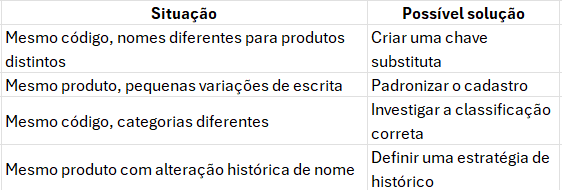

### Descobrindo quais campos estão diferentes

In [346]:
# Contar os valores distintos por produto
analise_divergencias = (
    dim_produtos
    .groupby("ID_Produto")
    .agg(
        Nomes_Distintos=("Nome_Produto", "nunique"),
        Categorias_Distintas=("Categoria", "nunique"),
        Subcategorias_Distintas=("Subcategoria", "nunique")
    )
)

# Mostrar somente os produtos divergentes
analise_divergencias = analise_divergencias.loc[
    inconsistencias.index
]

print(
    analise_divergencias.max()
)

analise_divergencias.head(15)

Nomes_Distintos            2
Categorias_Distintas       1
Subcategorias_Distintas    1
dtype: int64


,Nomes_Distintos,Categorias_Distintas,Subcategorias_Distintas
ID_Produto,,,
FUR-BO-10002213,2,1,1
FUR-CH-10001146,2,1,1
FUR-FU-10001473,2,1,1
FUR-FU-10004017,2,1,1
FUR-FU-10004091,2,1,1
FUR-FU-10004270,2,1,1
FUR-FU-10004848,2,1,1
FUR-FU-10004864,2,1,1
OFF-AP-10000576,2,1,1


O resultado mostra que as divergências cadastrais estão concentradas nos nomes dos produtos, enquanto as categorias e subcategorias permanecem consistentes.

### Recalculando os produtos divergentes

In [348]:
# Recriar a análise a partir da base final
analise_produtos = (
    df_final
    .groupby("ID_Produto")
    .agg(
        Nomes_Distintos=("Nome_Produto", "nunique"),
        Categorias_Distintas=("Categoria", "nunique"),
        Subcategorias_Distintas=("Subcategoria", "nunique")
    )
)

# Selecionar somente códigos com nomes diferentes
produtos_com_nomes_diferentes = analise_produtos[
    analise_produtos["Nomes_Distintos"] > 1
]

print(
    "Códigos com nomes diferentes:",
    len(produtos_com_nomes_diferentes)
)

# Mostrar os registros correspondentes
exemplos = (
    df_final[
        df_final["ID_Produto"].isin(
            produtos_com_nomes_diferentes.index
        )
    ][
        ["ID_Produto", "Nome_Produto",
         "Categoria", "Subcategoria"]
    ]
    .drop_duplicates()
    .sort_values(["ID_Produto", "Nome_Produto"])
)

display(exemplos.head(20))

Códigos com nomes diferentes: 32


,ID_Produto,Nome_Produto,Categoria,Subcategoria
2115,FUR-BO-10002213,DMI Eclipse Executive Suite Bookcases,Furniture,Bookcases
2471,FUR-BO-10002213,"Sauder Forest Hills Library, Woodland Oak Finish",Furniture,Bookcases
128,FUR-CH-10001146,"Global Task Chair, Black",Furniture,Chairs
66,FUR-CH-10001146,"Global Value Mid-Back Manager's Chair, Gray",Furniture,Chairs
1459,FUR-FU-10001473,DAX Wood Document Frame,Furniture,Furnishings
2204,FUR-FU-10001473,"Eldon Executive Woodline II Desk Accessories, ...",Furniture,Furnishings
3831,FUR-FU-10004017,"Executive Impressions 13"" Chairman Wall Clock",Furniture,Furnishings
234,FUR-FU-10004017,Tenex Contemporary Contur Chairmats for Low an...,Furniture,Furnishings
1385,FUR-FU-10004091,"Eldon 200 Class Desk Accessories, Black",Furniture,Furnishings
293,FUR-FU-10004091,"Howard Miller 13"" Diameter Goldtone Round Wall...",Furniture,Furnishings


Confirmado que os 32 códigos de produtos divergentes representam produtos realmente diferentes, e não apenas erros de digitação.

Por exemplo, o código FUR-BO-10002213 está associado a duas estantes diferentes. Portanto, não é possível utilizar somente ID_Produto como chave única da dimensão.

Será utilizada uma chave substituta (surrogate key), que é muito comum em modelagem dimensional.

A estrutura será semelhante a:

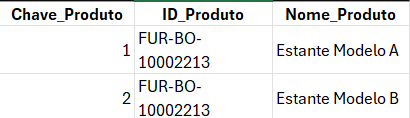

Assim, cada produto terá um identificador único dentro do modelo, mesmo quando o código original for reutilizado.

A tabela de vendas também receberá essa chave, permitindo criar um relacionamento de muitos-para-um com a dimensão de produtos.

A estratégia será utilizar a combinação ID_Produto + Nome_Produto para identificar cada produto distinto e gerar um identificador numérico exclusivo.

SK_Produto será a chave substituta.

Essa coluna será utilizada para relacionar a dimensão de produtos à tabela de vendas no Power BI.

### Criando a dimensão

In [350]:
# Selecionar os atributos dos produtos
dim_produtos = df_final[
    [
        "ID_Produto",
        "Nome_Produto",
        "Categoria",
        "Subcategoria"
    ]
].drop_duplicates().copy()

# Organizar os produtos
dim_produtos = dim_produtos.sort_values(
    ["ID_Produto", "Nome_Produto"]
).reset_index(drop=True)

# Criar a chave substituta
dim_produtos.insert(
    0,
    "SK_Produto",
    range(1, len(dim_produtos) + 1)
)

dim_produtos.head()

,SK_Produto,ID_Produto,Nome_Produto,Categoria,Subcategoria
0,1,FUR-BO-10000112,"Bush Birmingham Collection Bookcase, Dark Cherry",Furniture,Bookcases
1,2,FUR-BO-10000330,"Sauder Camden County Barrister Bookcase, Plank...",Furniture,Bookcases
2,3,FUR-BO-10000362,Sauder Inglewood Library Bookcases,Furniture,Bookcases
3,4,FUR-BO-10000468,O'Sullivan 2-Shelf Heavy-Duty Bookcases,Furniture,Bookcases
4,5,FUR-BO-10000711,"Hon Metal Bookcases, Gray",Furniture,Bookcases


Essa chave é adequada para esse projeto com uma base estática. Em sistemas com atualizações frequentes, seria necessário preservar o mapeamento das chaves entre diferentes cargas de dados.

### Validando a dimensão

In [352]:
print("Total de produtos:", len(dim_produtos))

print(
    "Chaves únicas:",
    dim_produtos["SK_Produto"].nunique()
)

print(
    "Chaves duplicadas:",
    dim_produtos["SK_Produto"].duplicated().sum()
)

print(
    "Combinações ID + Nome:",
    dim_produtos[
        ["ID_Produto", "Nome_Produto"]
    ].drop_duplicates().shape[0]
)

Total de produtos: 1893
Chaves únicas: 1893
Chaves duplicadas: 0
Combinações ID + Nome: 1893


### Adicionando a chave à tabela de vendas

In [354]:
# Criar uma cópia da base de vendas
fato_vendas = df_final.copy()

# Adicionar a chave substituta
fato_vendas = fato_vendas.merge(
    dim_produtos[
        ["SK_Produto", "ID_Produto", "Nome_Produto"]
    ],
    on=["ID_Produto", "Nome_Produto"],
    how="left",
    validate="many_to_one"
)

# Conferir os resultados
print("Registros na fato:", len(fato_vendas))

print(
    "Vendas sem chave de produto:",
    fato_vendas["SK_Produto"].isna().sum()
)

fato_vendas[
    ["ID_Linha", "ID_Produto",
     "Nome_Produto", "SK_Produto", "Valor_Venda"]
].head()

Registros na fato: 9800
Vendas sem chave de produto: 0


,ID_Linha,ID_Produto,Nome_Produto,SK_Produto,Valor_Venda
0,1,FUR-BO-10001798,Bush Somerset Collection Bookcase,13,261.9600
1,2,FUR-CH-10000454,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",57,731.9400
2,3,OFF-LA-10000240,Self-Adhesive Address Labels for Typewriters b...,960,14.6200
3,4,FUR-TA-10000577,Bretford CR4500 Series Slim Rectangular Table,328,957.5775
4,5,OFF-ST-10000760,Eldon Fold 'N Roll Cart System,1338,22.3680


Cada venda foi associada ao produto correto

O parâmetro validate="many_to_one" verifica se cada combinação de produto da tabela de vendas encontra no máximo uma correspondência na dimensão.

Isso é fundamental para evitar multiplicação de registros durante o relacionamento.

### Validando o faturamento após o relacionamento

Uma regra importante em projetos de BI é verificar se os relacionamentos alteraram indevidamente os valores financeiros.

In [356]:
# Faturamento antes do relacionamento
faturamento_original = df_final["Valor_Venda"].sum()

# Faturamento após o relacionamento
faturamento_fato = fato_vendas["Valor_Venda"].sum()

print(f"Faturamento original: {faturamento_original:,.2f}")
print(f"Faturamento na fato: {faturamento_fato:,.2f}")

# Testes automáticos
assert len(fato_vendas) == len(df_final)

assert fato_vendas["SK_Produto"].notna().all()

assert np.isclose(
    faturamento_original,
    faturamento_fato
)

print("Relacionamento validado com sucesso!")

Faturamento original: 2,261,536.78
Faturamento na fato: 2,261,536.78
Relacionamento validado com sucesso!


Isso confirma que o merge() não duplicou nem eliminou registros de vendas.

Assim ficará o relacionamento entre as tabelas no Power BI:

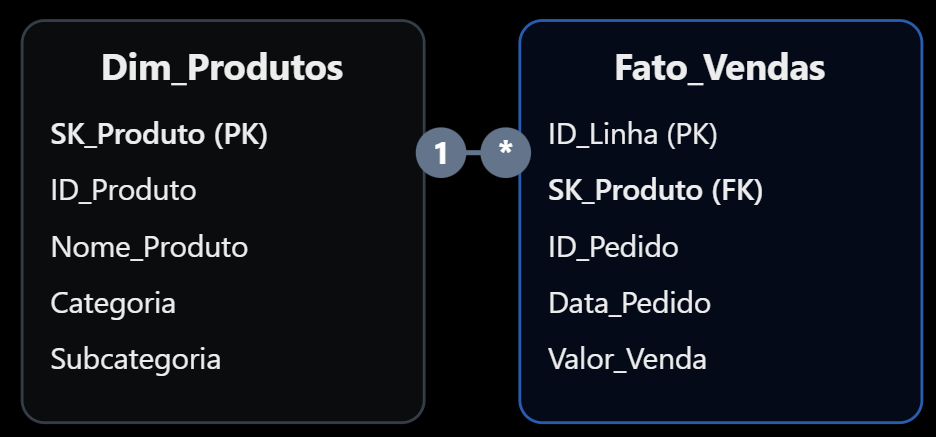

## 5.2 Dimensionando Tabela Dim_Clientes

Nossa tabela de clientes permitirá responder perguntas como:
- Quais clientes geram mais faturamento?
- Qual segmento representa a maior parcela das vendas?
- Quantos clientes distintos compraram em determinado período?
- Qual é o faturamento médio por cliente?

Na base, há três colunas relacionadas diretamente aos clientes:

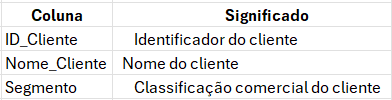

É preciso verificar se cada ID_Cliente está associado a um único nome e segmento.

Isso é importante para que não se crie uma dimensão de clientes utilizando drop_duplicates() sem verificar a consistência dos cadastros.

### Investigando os clientes

In [360]:
# Selecionar os atributos dos clientes
clientes = df_final[
    [
        "ID_Cliente",
        "Nome_Cliente",
        "Segmento"
    ]
].copy()

# Verificar quantidade de clientes
print(
    "Clientes únicos:",
    clientes["ID_Cliente"].nunique()
)

# Verificar possíveis divergências
analise_clientes = (
    clientes
    .groupby("ID_Cliente")
    .agg(
        Nomes_Distintos=("Nome_Cliente", "nunique"),
        Segmentos_Distintos=("Segmento", "nunique")
    )
)

# Selecionar clientes inconsistentes
clientes_divergentes = analise_clientes[
    (analise_clientes["Nomes_Distintos"] > 1)
    | (analise_clientes["Segmentos_Distintos"] > 1)
]

print(
    "Clientes com cadastros divergentes:",
    len(clientes_divergentes)
)

display(clientes_divergentes.head(10))

Clientes únicos: 793
Clientes com cadastros divergentes: 0


,Nomes_Distintos,Segmentos_Distintos
ID_Cliente,,


### Criando a dimensão de clientes

In [362]:
# Executar somente se não houver divergências
assert clientes_divergentes.empty, (
    "Existem clientes com cadastros divergentes."
)

dim_clientes = (
    clientes
    .drop_duplicates(subset=["ID_Cliente"])
    .sort_values("ID_Cliente")
    .reset_index(drop=True)
)

# Criar chave substituta
dim_clientes.insert(
    0,
    "SK_Cliente",
    range(1, len(dim_clientes) + 1)
)

dim_clientes.head()

,SK_Cliente,ID_Cliente,Nome_Cliente,Segmento
0,1,AA-10315,Alex Avila,Consumer
1,2,AA-10375,Allen Armold,Consumer
2,3,AA-10480,Andrew Allen,Consumer
3,4,AA-10645,Anna Andreadi,Consumer
4,5,AB-10015,Aaron Bergman,Consumer


### Relacionando os clientes à Fato_Vendas

In [364]:
# Adicionar chave do cliente à tabela fato
fato_vendas = fato_vendas.merge(
    dim_clientes[
        ["SK_Cliente", "ID_Cliente"]
    ],
    on="ID_Cliente",
    how="left",
    validate="many_to_one"
)

# Validar relacionamento
assert len(fato_vendas) == 9800

assert fato_vendas["SK_Cliente"].notna().all()

assert fato_vendas["ID_Linha"].is_unique

assert np.isclose(
    fato_vendas["Valor_Venda"].sum(),
    df_final["Valor_Venda"].sum()
)

print("Relacionamento com clientes validado!")

Relacionamento com clientes validado!


Como não houve divergências entre os clientes, a tabela Dim_Clientes foi criada.

Agora há duas dimensões relacionadas à tabela de vendas:

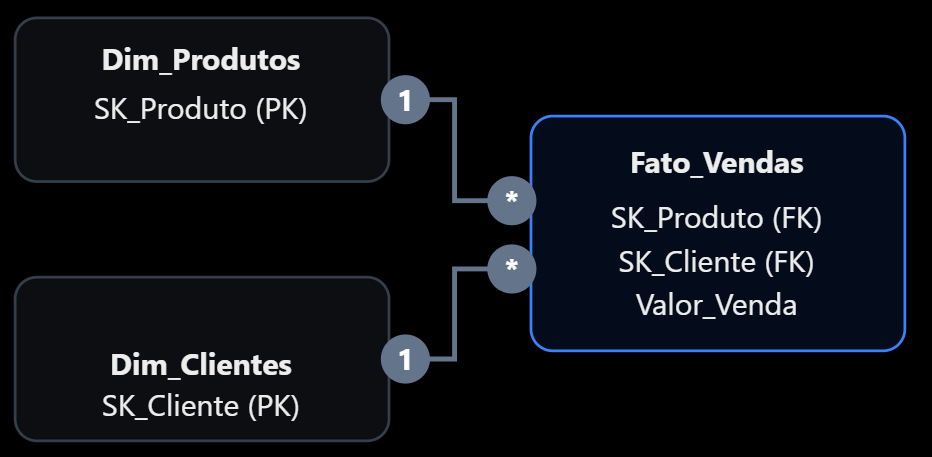

## 5.3 Dimensionando Tabela Dim_Calendario

A dimensão calendário permitirá analisar o faturamento por ano, trimestre, mês e dia da semana, além de comparar períodos.

Diferentemente das dimensões anteriores, não será necessário extrair apenas valores únicos das vendas. Será gerado uma sequência contínua de datas.

### Identificando o período da base

In [368]:
# Identificar o intervalo de datas
data_minima = df_final["Data_Pedido"].min()
data_maxima = df_final["Data_Pedido"].max()

print("Primeira venda:", data_minima)
print("Última venda:", data_maxima)

Primeira venda: 2015-01-03 00:00:00
Última venda: 2018-12-30 00:00:00


### Criando a tabela calendário

In [370]:
# Criar sequência contínua de datas
datas = pd.date_range(
    start=data_minima.replace(month=1, day=1),
    end=data_maxima.replace(month=12, day=31),
    freq="D"
)

# Criar dimensão calendário
dim_calendario = pd.DataFrame({
    "Data": datas
})

# Criar atributos temporais
dim_calendario["Ano"] = dim_calendario["Data"].dt.year

dim_calendario["Mes_Numero"] = dim_calendario["Data"].dt.month

dim_calendario["Trimestre"] = dim_calendario["Data"].dt.quarter

dim_calendario["Dia"] = dim_calendario["Data"].dt.day

dim_calendario["Dia_Semana_Numero"] = (
    dim_calendario["Data"].dt.dayofweek + 1
)

dim_calendario.head()

,Data,Ano,Mes_Numero,Trimestre,Dia,Dia_Semana_Numero
0,2015-01-01,2015,1,1,1,4
1,2015-01-02,2015,1,1,2,5
2,2015-01-03,2015,1,1,3,6
3,2015-01-04,2015,1,1,4,7
4,2015-01-05,2015,1,1,5,1


### Adicionando nomes dos meses e dias

In [372]:
meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

dias_semana = {
    1: "Segunda-feira",
    2: "Terça-feira",
    3: "Quarta-feira",
    4: "Quinta-feira",
    5: "Sexta-feira",
    6: "Sábado",
    7: "Domingo"
}

dim_calendario["Nome_Mes"] = (
    dim_calendario["Mes_Numero"].map(meses)
)

dim_calendario["Nome_Dia_Semana"] = (
    dim_calendario["Dia_Semana_Numero"].map(dias_semana)
)

# Criar campo Ano-Mês para gráficos
dim_calendario["Ano_Mes"] = (
    dim_calendario["Data"].dt.strftime("%Y-%m")
)

dim_calendario.head()

,Data,Ano,Mes_Numero,Trimestre,Dia,Dia_Semana_Numero,Nome_Mes,Nome_Dia_Semana,Ano_Mes
0,2015-01-01,2015,1,1,1,4,Janeiro,Quinta-feira,2015-01
1,2015-01-02,2015,1,1,2,5,Janeiro,Sexta-feira,2015-01
2,2015-01-03,2015,1,1,3,6,Janeiro,Sábado,2015-01
3,2015-01-04,2015,1,1,4,7,Janeiro,Domingo,2015-01
4,2015-01-05,2015,1,1,5,1,Janeiro,Segunda-feira,2015-01


Para deixar o dashboard mais intuitivo, os nomes em português serão adicionados.

No Power BI, poderemos usar Nome_Mes como rótulo e ordená-lo por Mes_Numero, evitando que os meses apareçam em ordem alfabética.

### Validando a dimensão calendário

In [374]:
print("Total de datas:", len(dim_calendario))

print("Primeira data:", dim_calendario["Data"].min())

print("Última data:", dim_calendario["Data"].max())

print(
    "Datas duplicadas:",
    dim_calendario["Data"].duplicated().sum()
)

print(
    "Valores ausentes:",
    dim_calendario.isnull().sum().sum()
)

# Testes automáticos
assert dim_calendario["Data"].is_unique
assert dim_calendario["Data"].notna().all()

print("Dimensão calendário validada!")

Total de datas: 1461
Primeira data: 2015-01-01 00:00:00
Última data: 2018-12-31 00:00:00
Datas duplicadas: 0
Valores ausentes: 0
Dimensão calendário validada!


### Relacionando a dimensão com a Fato_Vendas

Aqui há uma diferença em relação às dimensões anteriores: a própria data pode funcionar como chave, sem necessidade de criar um identificador numérico.

No Power BI, será criado um relacionamento de Dim_Calendario[Data] para Fato_Vendas[Data_Pedido], com cardinalidade de um para muitos e filtro em direção única.

Também tem Data_Envio na tabela fato. Inicialmente, será utilizado Data_Pedido como relacionamento principal. Depois há a possibilidade de criar um relacionamento inativo para analisar datas de envio com medidas DAX específicas.

In [376]:
# Garantir que as datas estejam normalizadas
fato_vendas["Data_Pedido"] = pd.to_datetime(
    fato_vendas["Data_Pedido"]
).dt.normalize()

# Verificar se todas as datas existem no calendário
datas_sem_correspondencia = ~fato_vendas[
    "Data_Pedido"
].isin(dim_calendario["Data"])

print(
    "Vendas sem data correspondente:",
    datas_sem_correspondencia.sum()
)

assert not datas_sem_correspondencia.any()

print("Relacionamento de datas validado!")

Vendas sem data correspondente: 0
Relacionamento de datas validado!


Assim fica o modelo estrela parcial

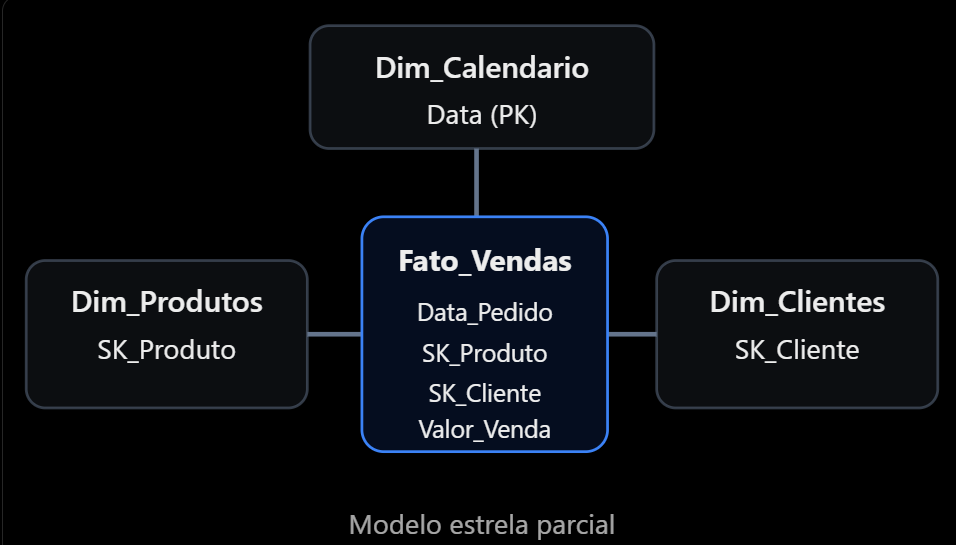

## 5.4 Dimensionando Tabela Dim_Localizacao

Essa dimensão permitirá analisar o faturamento por região, estado e cidade.

Ela também será útil para construir mapas no Power BI e identificar as localidades com maior participação nas vendas.

A base contém as seguintes colunas:

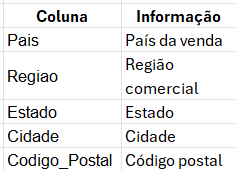

Existe um detalhe importante: uma mesma cidade pode aparecer em diferentes estados, e uma cidade pode possuir vários códigos postais.

Portanto, não é possível utilizar apenas o nome da cidade como chave da dimensão.

Será considerada a combinação completa dos atributos geográficos para identificar cada localização.

### Investigando as localidades

In [380]:
# Selecionar os atributos geográficos
colunas_localizacao = [
    "Pais",
    "Regiao",
    "Estado",
    "Cidade",
    "Codigo_Postal"
]

localizacoes = df_final[
    colunas_localizacao
].copy()

# Verificar os dados
print("Registros:", len(localizacoes))

print(
    "Países distintos:",
    localizacoes["Pais"].nunique()
)

print(
    "Regiões distintas:",
    localizacoes["Regiao"].nunique()
)

print(
    "Estados distintos:",
    localizacoes["Estado"].nunique()
)

print(
    "Cidades distintas:",
    localizacoes["Cidade"].nunique()
)

print(
    "Códigos postais ausentes:",
    localizacoes["Codigo_Postal"].isna().sum()
)

Registros: 9800
Países distintos: 1
Regiões distintas: 4
Estados distintos: 49
Cidades distintas: 529
Códigos postais ausentes: 11



Por que analisar isso primeiro?

É preciso entender a granularidade geográfica antes de criar a dimensão.

Por exemplo, se for utilizado somente Cidade, vendas de cidades homônimas poderiam ser agrupadas incorretamente.

Além disso, os códigos postais ausentes exigem cuidado: não serão inventados valores para preenchê-los.

A chave SK_Localizacao identificará cada combinação geográfica.

### Criando a dimensão

Assim como foi feito com produtos e clientes, essa chave será utilizada na tabela fato.

In [382]:
# Criar a dimensão de localização
dim_localizacao = (
    localizacoes
    .drop_duplicates()
    .sort_values(
        ["Pais", "Estado", "Cidade", "Codigo_Postal"],
        na_position="last"
    )
    .reset_index(drop=True)
)

# Criar chave substituta
dim_localizacao.insert(
    0,
    "SK_Localizacao",
    range(1, len(dim_localizacao) + 1)
)

print(
    "Localizações distintas:",
    len(dim_localizacao)
)

dim_localizacao.head()

Localizações distintas: 628


,SK_Localizacao,Pais,Regiao,Estado,Cidade,Codigo_Postal
0,1,United States,South,Alabama,Auburn,36830
1,2,United States,South,Alabama,Decatur,35601
2,3,United States,South,Alabama,Florence,35630
3,4,United States,South,Alabama,Hoover,35244
4,5,United States,South,Alabama,Huntsville,35810


A chave foi adicionada a tabela fato.

O Pandas consegue relacionar valores nulos entre si durante um merge(), diferentemente do comportamento habitual de NULL em relacionamentos SQL.

Isso permite associar registros com código postal ausente, desde que os demais atributos geográficos sejam iguais.

### Relacionando a dimensão à Fato_Vendas

In [384]:
# Adicionar a chave de localização
fato_vendas = fato_vendas.merge(
    dim_localizacao,
    on=colunas_localizacao,
    how="left",
    validate="many_to_one"
)

# Verificar o relacionamento
print(
    "Registros na fato:",
    len(fato_vendas)
)

print(
    "Vendas sem localização:",
    fato_vendas["SK_Localizacao"].isna().sum()
)

print(
    "Faturamento:",
    round(fato_vendas["Valor_Venda"].sum(), 2)
)

Registros na fato: 9800
Vendas sem localização: 0
Faturamento: 2261536.78


### Validando a integridade

In [386]:
# Verificar a unicidade da dimensão
assert dim_localizacao["SK_Localizacao"].is_unique

# Verificar o número de vendas
assert len(fato_vendas) == len(df_final)

# Verificar chaves ausentes
assert fato_vendas["SK_Localizacao"].notna().all()

# Verificar se o faturamento foi preservado
assert np.isclose(
    fato_vendas["Valor_Venda"].sum(),
    df_final["Valor_Venda"].sum()
)

# Verificar se as linhas continuam únicas
assert fato_vendas["ID_Linha"].is_unique

print("Dim_Localizacao validada!")
print("Relacionamento com Fato_Vendas validado!")

Dim_Localizacao validada!
Relacionamento com Fato_Vendas validado!


Modelo estrela parcial com a adição da tabela Dim_Localizacao:

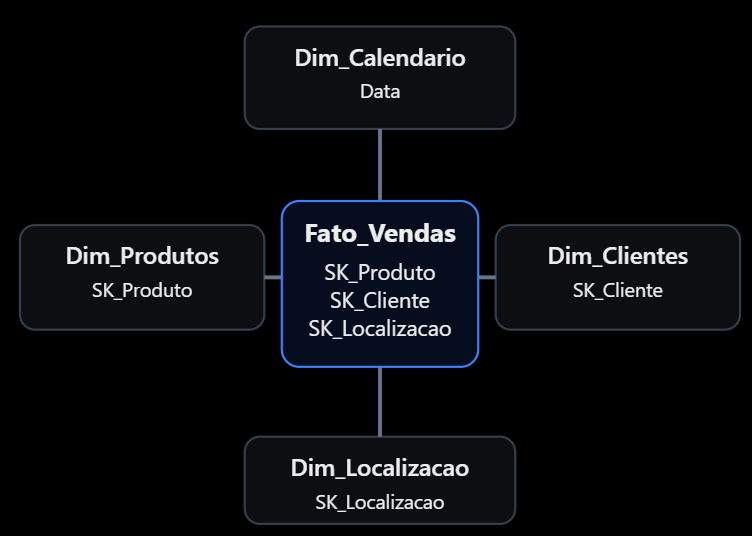

## 5.5 Tabela Fato_Vendas


Agora será aplicado um conceito importante de modelagem dimensional: a tabela fato deve conter as informações necessárias para identificar e medir as transações, enquanto os atributos descritivos ficam nas dimensões.

Por exemplo, não é necessário manter Nome_Produto, Categoria e Subcategoria na tabela fato, porque essas informações já existem na Dim_Produtos.

Antes de selecionar as colunas, é preciso definir o que representa uma linha da tabela.

Nesse projeto:

Cada linha da Fato_Vendas representa um item registrado em um pedido.

Isso significa que um mesmo ID_Pedido pode aparecer em várias linhas, mas ID_Linha identifica cada registro individualmente.

Essa definição é essencial para calcular corretamente o faturamento, a quantidade de pedidos e o ticket médio.

### Selecionando as colunas da tabela fato

In [390]:
# Selecionar apenas as colunas necessárias
colunas_fato = [
    "ID_Linha",
    "ID_Pedido",
    "Data_Pedido",
    "Data_Envio",
    "Modo_Envio",
    "SK_Produto",
    "SK_Cliente",
    "SK_Localizacao",
    "Valor_Venda",
    "Dias_Envio"
]

fato_vendas_final = fato_vendas[
    colunas_fato
].copy()

# Visualizar a estrutura
print(fato_vendas_final.shape)

display(fato_vendas_final.head())

(9800, 10)


,ID_Linha,ID_Pedido,Data_Pedido,Data_Envio,Modo_Envio,SK_Produto,SK_Cliente,SK_Localizacao,Valor_Venda,Dias_Envio
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,13,144,270,261.9600,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,57,144,270,731.9400,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,960,238,66,14.6200,4
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,328,706,158,957.5775,7
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,1338,706,158,22.3680,7


Por que manter essas colunas?

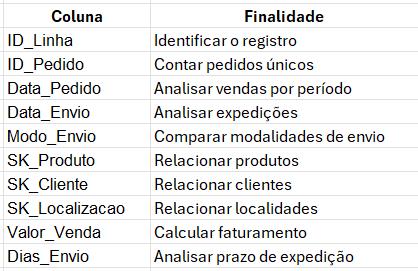

Mais adiante, poderá ser criada uma dimensão específica para modalidades de envio. Por enquanto, será mantido Modo_Envio na tabela fato, pois é um atributo descritivo de baixa cardinalidade.

### Validando a tabela fato

In [392]:
# Conferir quantidade de registros
assert len(fato_vendas_final) == 9800

# Conferir identificadores únicos
assert fato_vendas_final["ID_Linha"].is_unique

# Conferir chaves de relacionamento
for coluna in [
    "SK_Produto",
    "SK_Cliente",
    "SK_Localizacao"
]:
    assert fato_vendas_final[coluna].notna().all()

# Conferir valores financeiros
assert np.isclose(
    fato_vendas_final["Valor_Venda"].sum(),
    df_final["Valor_Venda"].sum()
)

print("Fato_Vendas validada com sucesso!")

Fato_Vendas validada com sucesso!


### Criando nossos primeiros indicadores

Antes de importar para o Power BI, serão calculados três indicadores usando Python. Eles servirão como referência para validar as medidas DAX posteriormente.

Atenção: o ticket médio é calculado por pedido, e não por linha da tabela.

Um pedido pode conter vários produtos, portanto dividir o faturamento por 9.800 produziria uma média por item registrado, não o ticket médio por pedido.

In [394]:
# Faturamento total
faturamento = fato_vendas_final["Valor_Venda"].sum()

# Quantidade de pedidos únicos
total_pedidos = fato_vendas_final["ID_Pedido"].nunique()

# Ticket médio por pedido
ticket_medio = faturamento / total_pedidos

print(f"Faturamento: {faturamento:,.2f}")
print(f"Pedidos únicos: {total_pedidos:,}")
print(f"Ticket médio: {ticket_medio:,.2f}")

Faturamento: 2,261,536.78
Pedidos únicos: 4,922
Ticket médio: 459.48


### Exportando nosso modelo estrela

In [396]:
pasta_modelo = Path("../dados_tratados/modelo_estrela")

pasta_modelo.mkdir(
    parents=True,
    exist_ok=True
)

tabelas = {
    "Dim_Produtos": dim_produtos,
    "Dim_Clientes": dim_clientes,
    "Dim_Calendario": dim_calendario,
    "Dim_Localizacao": dim_localizacao,
    "Fato_Vendas": fato_vendas_final
}

for nome, tabela in tabelas.items():
    caminho = pasta_modelo / f"{nome}.csv"

    tabela.to_csv(
        caminho,
        sep=";",
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d",
        float_format="%.4f"
    )

    print(
        f"{nome}: {len(tabela)} registros exportados"
    )

Dim_Produtos: 1893 registros exportados
Dim_Clientes: 793 registros exportados
Dim_Calendario: 1461 registros exportados
Dim_Localizacao: 628 registros exportados
Fato_Vendas: 9800 registros exportados


# 6. Construção do módulo de estoque

Existe uma limitação importante na base original: ela contém o valor das vendas, mas não possui quantidade vendida, estoque atual ou estoque mínimo.

Por isso, será construída uma base de estoque simulada, com premissas documentadas, para demonstrar como um comércio poderia utilizar o dashboard para controlar mercadorias e identificar necessidades de reposição.

Os indicadores simulados não serão apresentados como se fossem dados reais.

O objetivo é desenvolver uma estrutura capaz de responder perguntas como: quais produtos estão abaixo do estoque mínimo, quanto capital está imobilizado em mercadorias e quais produtos precisam de reposição?

Para isso, duas tabelas adicionais serão construídas:
- Fato_Estoque: saldo disponível, estoque mínimo e custo unitário simulado por produto.
- Fato_Movimentacao_Estoque: movimentações simuladas de entrada e saída, que poderão ser utilizadas posteriormente para analisar o giro.

## 6.1 Gerando Estoque Simulado

Serão utilizados os 1.893 produtos da nossa Dim_Produtos.

Para tornar os dados reproduzíveis, será usado um gerador aleatório com uma semente fixa.

In [401]:
# Criar gerador de números aleatórios
rng = np.random.default_rng(seed=42)

# Selecionar produtos
fato_estoque = dim_produtos[
    ["SK_Produto"]
].copy()

# Simular saldo de estoque entre 0 e 200 unidades
fato_estoque["Estoque_Atual"] = rng.integers(
    low=0,
    high=201,
    size=len(fato_estoque)
)

# Simular estoque mínimo entre 10 e 50 unidades
fato_estoque["Estoque_Minimo"] = rng.integers(
    low=10,
    high=51,
    size=len(fato_estoque)
)

fato_estoque.head()

,SK_Produto,Estoque_Atual,Estoque_Minimo
0,1,17,39
1,2,155,15
2,3,131,44
3,4,88,33
4,5,87,45


np.random.default_rng(seed=42) cria um gerador de números aleatórios reproduzível. Assim, ao executar novamente o código, serão obtidos os mesmos resultados, desde que a ordem dos produtos permaneça igual.

rng.integers() gera números inteiros dentro de um intervalo. O limite superior não é incluído, por isso é utilizado high=201 para permitir estoque de até 200 unidades.

Essa é uma primeira simulação didática. Mais adiante, será possível aprimorá-la para criar estoques coerentes com diferentes categorias de produtos.

### Simulando o custo unitário

Para calcular o valor financeiro do estoque, é preciso um custo de aquisição.

Como não há esse dado, custos simulados entre 5 e 500 unidades monetárias serão gerados.

O Valor_Estoque representa o valor estimado do estoque ao custo, e não o faturamento potencial de venda.

In [404]:
# Simular custo unitário
fato_estoque["Custo_Unitario"] = np.round(
    rng.uniform(
        low=5,
        high=500,
        size=len(fato_estoque)
    ),
    2
)

# Calcular valor total do estoque
fato_estoque["Valor_Estoque"] = (
    fato_estoque["Estoque_Atual"]
    * fato_estoque["Custo_Unitario"]
)

fato_estoque.head()

,SK_Produto,Estoque_Atual,Estoque_Minimo,Custo_Unitario,Valor_Estoque
0,1,17,39,15.47,262.99
1,2,155,15,161.60,25048.00
2,3,131,44,92.62,12133.22
3,4,88,33,329.66,29010.08
4,5,87,45,141.14,12279.18


Observe que usamos np.select() para classificar os produtos conforme diferentes condições.

A ordem importa: verificamos primeiro se o estoque é zero e depois se está abaixo do mínimo.

### Criando indicadores de reposição

In [406]:
# Criar status de estoque
fato_estoque["Status_Estoque"] = np.select(
    [
        fato_estoque["Estoque_Atual"] == 0,
        fato_estoque["Estoque_Atual"]
        < fato_estoque["Estoque_Minimo"]
    ],
    [
        "Sem estoque",
        "Abaixo do mínimo"
    ],
    default="Estoque adequado"
)

# Calcular necessidade de reposição
fato_estoque["Necessidade_Reposicao"] = np.maximum(
    fato_estoque["Estoque_Minimo"]
    - fato_estoque["Estoque_Atual"],
    0
)

print(fato_estoque["Status_Estoque"].value_counts())

Status_Estoque
Estoque adequado    1595
Abaixo do mínimo     288
Sem estoque           10
Name: count, dtype: int64


### Validando o estoque simulado

In [408]:
# Validar quantidade de produtos
assert len(fato_estoque) == len(dim_produtos)

# Validar unicidade das chaves
assert fato_estoque["SK_Produto"].is_unique

# Verificar se todas as chaves existem na dimensão
assert fato_estoque["SK_Produto"].isin(
    dim_produtos["SK_Produto"]
).all()

# Verificar valores negativos
assert (fato_estoque["Estoque_Atual"] >= 0).all()
assert (fato_estoque["Custo_Unitario"] >= 0).all()
assert (fato_estoque["Necessidade_Reposicao"] >= 0).all()

print("Estoque simulado validado!")

Estoque simulado validado!


### Calculando nossos primeiros indicadores de estoque

In [410]:
# Quantidade total em estoque
quantidade_estoque = fato_estoque["Estoque_Atual"].sum()

# Valor financeiro total
valor_estoque = fato_estoque["Valor_Estoque"].sum()

# Produtos abaixo do mínimo ou zerados
produtos_criticos = (
    fato_estoque["Status_Estoque"]
    != "Estoque adequado"
).sum()

# Quantidade necessária para reposição
reposicao_total = fato_estoque[
    "Necessidade_Reposicao"
].sum()

print(f"Unidades em estoque: {quantidade_estoque:,}")
print(f"Valor do estoque: {valor_estoque:,.2f}")
print(f"Produtos críticos: {produtos_criticos}")
print(f"Unidades para reposição: {reposicao_total:,}")

Unidades em estoque: 189,501
Valor do estoque: 48,471,236.11
Produtos críticos: 298
Unidades para reposição: 5,054


Esses indicadores serão apresentados em uma página específica do Power BI, identificada como Estoque Simulado.

A simulação é independente das vendas históricas. Portanto, ainda não é possível calcular giro de estoque real nem cobertura de estoque com esses dados. Para isso, é preciso construir uma simulação consistente de quantidades e movimentações.

### Distribuição dos produtos por situação

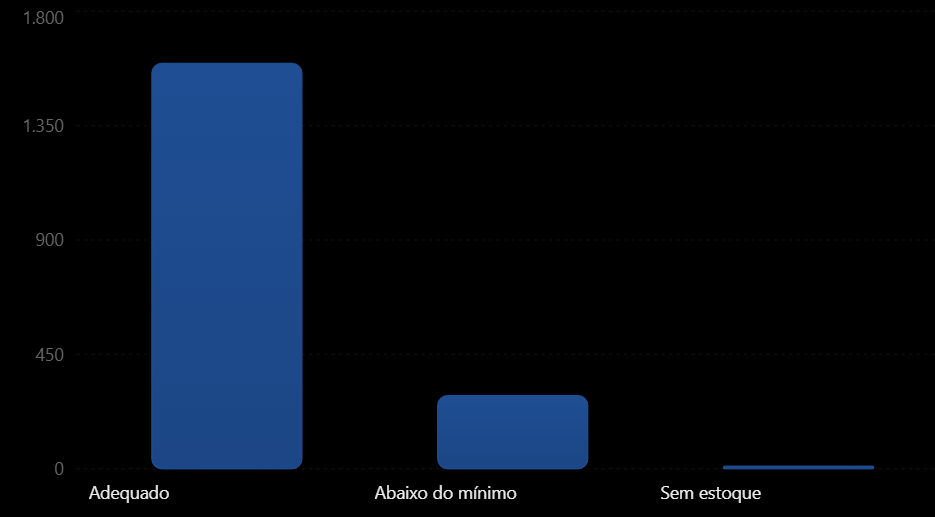

Aproximadamente 15,7% dos produtos estão em situação crítica. Isso significa que, no cenário simulado, quase um em cada seis produtos exige atenção.

Uma observação relevante: o valor total do estoque simulado é muito superior ao faturamento histórico da base. Isso ocorre porque geramos quantidades e custos aleatoriamente, sem considerar os preços e a demanda dos produtos.

## 6.2 Analisando relação Estoque x Vendas

Em vez de gerar novos números imediatamente, o desempenho comercial dos produtos será investigado.

A intenção é utilizar o faturamento histórico como uma referência para construir uma simulação de estoque mais realista.

Importante: faturamento não representa quantidade vendida. Por isso, essa informação será usada apenas como um indicador aproximado de relevância comercial, e não como giro de estoque.

### Calculando o faturamento por produto

In [416]:
# Agrupar vendas por produto
vendas_por_produto = (
    fato_vendas_final
    .groupby("SK_Produto")
    .agg(
        Faturamento_Total=("Valor_Venda", "sum"),
        Linhas_Venda=("ID_Linha", "count"),
        Pedidos_Distintos=("ID_Pedido", "nunique")
    )
    .reset_index()
)

print(
    "Produtos com vendas:",
    len(vendas_por_produto)
)

display(vendas_por_produto.head())

Produtos com vendas: 1893


,SK_Produto,Faturamento_Total,Linhas_Venda,Pedidos_Distintos
0,1,825.174,1,1
1,2,1064.624,3,3
2,3,2154.348,5,5
3,4,723.842,6,6
4,5,851.760,2,2


Aqui estão sendo criados três indicadores:

- Faturamento_Total: soma dos valores vendidos por produto.
- Linhas_Venda: quantidade de registros de venda do produto.
- Pedidos_Distintos: número de pedidos diferentes em que o produto apareceu.

Nenhum desses indicadores deve ser interpretado como quantidade de unidades vendidas.

### Relacionando as vendas ao estoque

Essa análise nos permitirá observar se os produtos de maior faturamento estão adequadamente abastecidos no cenário simulado.

Por enquanto, a relação entre vendas e estoque será apenas exploratória, já que os saldos foram gerados aleatoriamente.

In [420]:
# Relacionar estoque e desempenho comercial
estoque_analise = fato_estoque.merge(
    vendas_por_produto,
    on="SK_Produto",
    how="left",
    validate="one_to_one"
)

# Conferir relacionamento
print(
    "Produtos no estoque:",
    len(estoque_analise)
)

print(
    "Produtos sem histórico de vendas:",
    estoque_analise["Faturamento_Total"].isna().sum()
)

# Validar integridade
assert len(estoque_analise) == len(fato_estoque)

assert estoque_analise["SK_Produto"].is_unique

print("Relacionamento validado!")

Produtos no estoque: 1893
Produtos sem histórico de vendas: 0
Relacionamento validado!


### Identificando os produtos de maior faturamento

In [422]:
# Adicionar informações descritivas
ranking_produtos = estoque_analise.merge(
    dim_produtos[
        [
            "SK_Produto",
            "Nome_Produto",
            "Categoria",
            "Subcategoria"
        ]
    ],
    on="SK_Produto",
    how="left",
    validate="one_to_one"
)

# Selecionar os dez maiores faturamentos
top_10 = (
    ranking_produtos
    .sort_values(
        "Faturamento_Total",
        ascending=False
    )
    .head(10)
)

display(
    top_10[
        [
            "Nome_Produto",
            "Categoria",
            "Faturamento_Total",
            "Estoque_Atual",
            "Estoque_Minimo",
            "Status_Estoque"
        ]
    ]
)

,Nome_Produto,Categoria,Faturamento_Total,Estoque_Atual,Estoque_Minimo,Status_Estoque
1639,Canon imageCLASS 2200 Advanced Copier,Technology,61599.824,54,12,Estoque adequado
787,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.384,137,14,Estoque adequado
1668,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.480,107,16,Estoque adequado
82,HON 5400 Series Task Chairs for Big and Tall,Furniture,21870.576,32,12,Estoque adequado
701,GBC DocuBind TL300 Electric Binding System,Office Supplies,19823.479,123,22,Estoque adequado
667,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,19024.500,173,33,Estoque adequado
1629,Hewlett Packard LaserJet 3310 Copier,Technology,18839.686,25,43,Abaixo do mínimo
1656,HP Designjet T520 Inkjet Large Format Printer ...,Technology,18374.895,170,36,Estoque adequado
858,GBC DocuBind P400 Electric Binding System,Office Supplies,17965.068,134,13,Estoque adequado
1442,High Speed Automatic Electric Letter Opener,Office Supplies,17030.312,187,19,Estoque adequado


Um resultado chama a atenção:

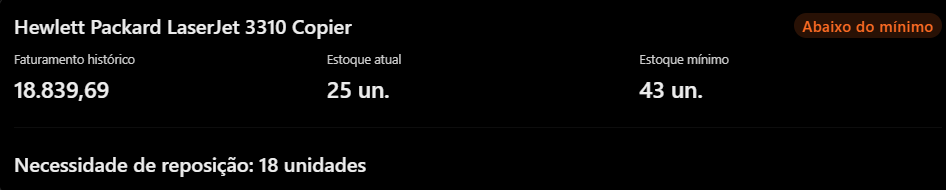

Esse produto está entre os dez maiores faturamentos históricos e, na simulação, apresenta estoque abaixo do mínimo.

É exatamente o tipo de situação que será destacada no dashboard: produtos comercialmente relevantes que precisam de atenção no abastecimento.

Entretanto, o estoque atual foi gerado aleatoriamente. Por isso, essa situação é ilustrativa, não um diagnóstico real de uma empresa.

### O que será aprimorado nas próximas etapas

Na próxima etapa, uma versão mais coerente do estoque será construída utilizando:

1. Relevância comercial: produtos com maior faturamento histórico poderão receber parâmetros de estoque diferentes.
2. Custos simulados: serão definidas premissas explícitas para os custos, evitando valores completamente desconectados do perfil comercial.
3. Estoque mínimo: regras de reposição conforme a classificação dos produtos serão estabelecidas.
4. Rastreabilidade: a identificação de que todos os dados de estoque são simulados será mantida.

Também será necessário definir uma data de referência para o estoque, pois as vendas históricas abrangem 2015 a 2018, enquanto o estoque representa uma posição em um momento específico.

## 6.3 Análise Curva ABC

Antes de refazer a simulação de estoque, uma classificação ABC baseada no faturamento será construída.

Essa classificação é muito utilizada na gestão de estoques para identificar os produtos com maior importância financeira.

Serão adotados os seguintes critérios:

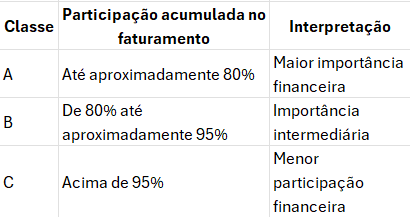

Os limites de 80% e 95% são convenções de análise, não regras obrigatórias.

### Calculando o faturamento acumulado

In [428]:
# Ordenar produtos por faturamento
analise_abc = (
    ranking_produtos
    .sort_values(
        "Faturamento_Total",
        ascending=False
    )
    .reset_index(drop=True)
)

# Calcular participação individual no faturamento
analise_abc["Participacao_Faturamento"] = (
    analise_abc["Faturamento_Total"]
    / analise_abc["Faturamento_Total"].sum()
)

# Calcular participação acumulada
analise_abc["Participacao_Acumulada"] = (
    analise_abc["Participacao_Faturamento"].cumsum()
)

display(
    analise_abc[
        [
            "Nome_Produto",
            "Faturamento_Total",
            "Participacao_Faturamento",
            "Participacao_Acumulada"
        ]
    ].head(10)
)

,Nome_Produto,Faturamento_Total,Participacao_Faturamento,Participacao_Acumulada
0,Canon imageCLASS 2200 Advanced Copier,61599.824,0.027238,0.027238
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,0.012139,0.039377
2,Cisco TelePresence System EX90 Videoconferenci...,22638.480,0.010010,0.049388
3,HON 5400 Series Task Chairs for Big and Tall,21870.576,0.009671,0.059058
4,GBC DocuBind TL300 Electric Binding System,19823.479,0.008765,0.067824
5,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,0.008412,0.076236
6,Hewlett Packard LaserJet 3310 Copier,18839.686,0.008330,0.084566
7,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,0.008125,0.092691
8,GBC DocuBind P400 Electric Binding System,17965.068,0.007944,0.100635
9,High Speed Automatic Electric Letter Opener,17030.312,0.007530,0.108165


Será utilizada a tabela ranking_produtos, que já contém os dados comerciais e de estoque.

A coluna Participacao_Faturamento representa quanto cada produto contribui para o faturamento total.

Já Participacao_Acumulada soma progressivamente essas participações, começando pelos produtos de maior faturamento.

Assim é possível descobrir quantos produtos concentram aproximadamente 80% das vendas.

### Criando a classificação ABC

Agora será atribuido uma classe a cada produto.

Para evitar que um produto seja dividido entre duas classes, será considerada a participação acumulada antes de sua inclusão. Dessa forma, o produto que ultrapassar cada limite permanecerá na classe anterior.

In [430]:
# Participação acumulada antes de cada produto
acumulado_anterior = (
    analise_abc["Participacao_Acumulada"]
    - analise_abc["Participacao_Faturamento"]
)

# Classificar os produtos
analise_abc["Classe_ABC"] = np.select(
    [
        acumulado_anterior < 0.80,
        acumulado_anterior < 0.95
    ],
    [
        "A",
        "B"
    ],
    default="C"
)

print(
    analise_abc["Classe_ABC"].value_counts()
)

Classe_ABC
C    972
B    500
A    421
Name: count, dtype: int64


### Resumindo os resultados

In [432]:
# Resumo da classificação ABC
resumo_abc = (
    analise_abc
    .groupby("Classe_ABC")
    .agg(
        Quantidade_Produtos=("SK_Produto", "count"),
        Faturamento=("Faturamento_Total", "sum")
    )
    .reset_index()
)

# Participação de cada classe no faturamento
resumo_abc["Participacao_Percentual"] = (
    resumo_abc["Faturamento"]
    / resumo_abc["Faturamento"].sum()
    * 100
)

# Participação de cada classe na quantidade de produtos
resumo_abc["Percentual_Produtos"] = (
    resumo_abc["Quantidade_Produtos"]
    / resumo_abc["Quantidade_Produtos"].sum()
    * 100
)

display(resumo_abc)

,Classe_ABC,Quantidade_Produtos,Faturamento,Participacao_Percentual,Percentual_Produtos
0,A,421,1.810364e+06,80.050180,22.239831
1,B,500,3.383422e+05,14.960719,26.413101
2,C,972,1.128304e+05,4.989102,51.347068


### Validando a classificação

In [434]:
# Todos os produtos precisam ter classificação
assert analise_abc["Classe_ABC"].notna().all()

# Não podemos perder produtos
assert len(analise_abc) == len(dim_produtos)

# Cada produto deve aparecer uma vez
assert analise_abc["SK_Produto"].is_unique

# A participação total deve ser 100%
assert np.isclose(
    analise_abc["Participacao_Faturamento"].sum(),
    1.0
)

# Faturamento deve permanecer igual
assert np.isclose(
    analise_abc["Faturamento_Total"].sum(),
    fato_vendas_final["Valor_Venda"].sum()
)

print("Classificação ABC validada!")

Classificação ABC validada!


### Análise da classificação ABC

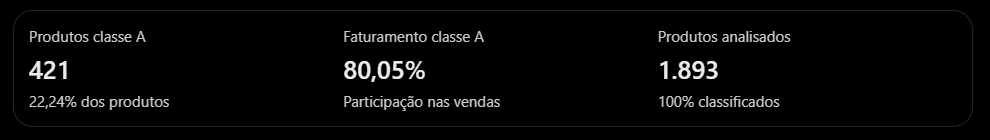

Comparação entre participação dos produtos e participação no faturamento.

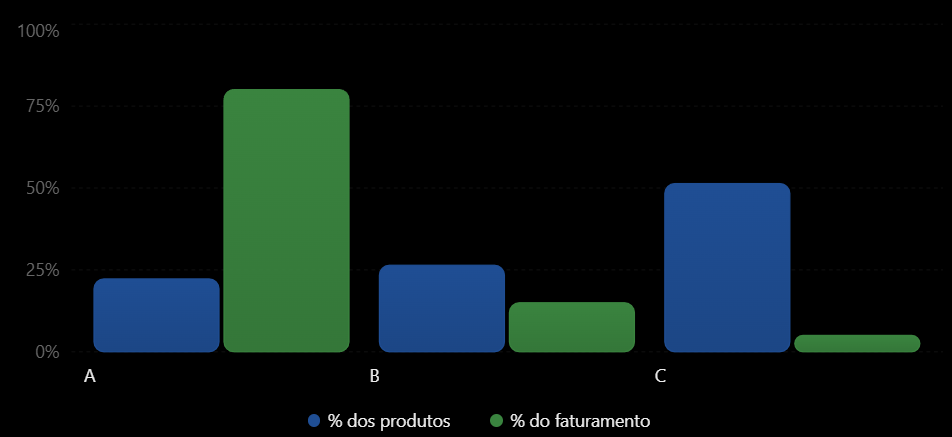

O que esses números significam?

Os produtos da classe A representam uma parcela relativamente pequena do catálogo, mas concentram a maior parte do faturamento histórico. Por isso, merecem atenção especial nas análises de disponibilidade e reposição.

Já os produtos da classe C representam mais da metade do catálogo, mas contribuem com apenas 4,99% do faturamento.

Isso não significa necessariamente que o estoque de todos os produtos C deve ser reduzido. Alguns podem ser essenciais para o mix comercial ou ter demanda frequente com preços baixos.

Um cuidado importante: a classificação ABC foi baseada em faturamento, não em quantidade vendida ou margem de lucro.

Na próxima etapa, será utilizada a classificação ABC para criar parâmetros simulados de estoque mais consistentes.

Por exemplo, será possível definir políticas diferentes de reposição para produtos A, B e C, documentando claramente as premissas adotadas.

Também será construída uma análise cruzada entre classe ABC e status de estoque, permitindo identificar quantos produtos de alta relevância financeira estão abaixo do mínimo.

Essa combinação será um dos principais diferenciais do dashboard.

## 6.4 Criando políticas de estoque por classe ABC

A primeira versão gerou estoques e custos completamente aleatórios. Isso foi útil para testar a estrutura, mas não é o ideal para um portfólio profissional.

Nesta segunda versão, serão estabelecidas premissas de reposição diferentes para cada classe.

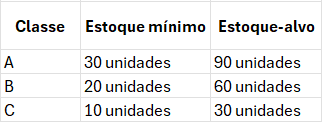

Esses valores são hipóteses da simulação, não recomendações universais de gestão de estoque. Em uma operação real, os parâmetros dependeriam da demanda em unidades, do prazo de reposição e do nível de serviço desejado.

O estoque-alvo representa a quantidade que a empresa gostaría de atingir após uma reposição planejada.

### Adicionando a classificação ABC ao estoque

In [441]:
# Criar segunda versão do estoque
fato_estoque_v2 = fato_estoque.copy()

# Adicionar classificação ABC
fato_estoque_v2 = fato_estoque_v2.merge(
    analise_abc[
        ["SK_Produto", "Classe_ABC"]
    ],
    on="SK_Produto",
    how="left",
    validate="one_to_one"
)

# Validar relacionamento
assert len(fato_estoque_v2) == len(dim_produtos)
assert fato_estoque_v2["Classe_ABC"].notna().all()

print(
    fato_estoque_v2["Classe_ABC"].value_counts()
)

Classe_ABC
C    972
B    500
A    421
Name: count, dtype: int64


### Aplicando os novos parâmetros

In [443]:
# Definir políticas simuladas
politicas_estoque = {
    "A": {"minimo": 30, "alvo": 90},
    "B": {"minimo": 20, "alvo": 60},
    "C": {"minimo": 10, "alvo": 30}
}

# Aplicar estoque mínimo por classe
fato_estoque_v2["Estoque_Minimo"] = (
    fato_estoque_v2["Classe_ABC"]
    .map({
        classe: politica["minimo"]
        for classe, politica in politicas_estoque.items()
    })
)

# Aplicar estoque-alvo
fato_estoque_v2["Estoque_Alvo"] = (
    fato_estoque_v2["Classe_ABC"]
    .map({
        classe: politica["alvo"]
        for classe, politica in politicas_estoque.items()
    })
)

display(fato_estoque_v2.head())

,SK_Produto,Estoque_Atual,Estoque_Minimo,Custo_Unitario,Valor_Estoque,Status_Estoque,Necessidade_Reposicao,Classe_ABC,Estoque_Alvo
0,1,17,20,15.47,262.99,Abaixo do mínimo,22,B,60
1,2,155,20,161.60,25048.00,Estoque adequado,0,B,60
2,3,131,30,92.62,12133.22,Estoque adequado,0,A,90
3,4,88,20,329.66,29010.08,Estoque adequado,0,B,60
4,5,87,20,141.14,12279.18,Estoque adequado,0,B,60


Até aqui, foram alterados apenas os parâmetros de estoque mínimo e estoque-alvo. O saldo atual e os custos continuam sendo os valores simulados anteriormente.

### Recalculando os indicadores

In [445]:
# Atualizar status de estoque
fato_estoque_v2["Status_Estoque"] = np.select(
    [
        fato_estoque_v2["Estoque_Atual"] == 0,
        fato_estoque_v2["Estoque_Atual"]
        < fato_estoque_v2["Estoque_Minimo"]
    ],
    [
        "Sem estoque",
        "Abaixo do mínimo"
    ],
    default="Estoque adequado"
)

# Quantidade para atingir o mínimo
fato_estoque_v2["Necessidade_Reposicao"] = np.maximum(
    fato_estoque_v2["Estoque_Minimo"]
    - fato_estoque_v2["Estoque_Atual"],
    0
)

# Quantidade para atingir o estoque-alvo
# Somente produtos críticos entram na sugestão de compra
fato_estoque_v2["Sugestao_Compra"] = np.where(
    fato_estoque_v2["Estoque_Atual"]
    < fato_estoque_v2["Estoque_Minimo"],

    np.maximum(
        fato_estoque_v2["Estoque_Alvo"]
        - fato_estoque_v2["Estoque_Atual"],
        0
    ),

    0
)

display(
    fato_estoque_v2[
        [
            "SK_Produto",
            "Classe_ABC",
            "Estoque_Atual",
            "Estoque_Minimo",
            "Estoque_Alvo",
            "Status_Estoque",
            "Necessidade_Reposicao",
            "Sugestao_Compra"
        ]
    ].head(10)
)

,SK_Produto,Classe_ABC,Estoque_Atual,Estoque_Minimo,Estoque_Alvo,Status_Estoque,Necessidade_Reposicao,Sugestao_Compra
0,1,B,17,20,60,Abaixo do mínimo,3,43
1,2,B,155,20,60,Estoque adequado,0,0
2,3,A,131,30,90,Estoque adequado,0,0
3,4,B,88,20,60,Estoque adequado,0,0
4,5,B,87,20,60,Estoque adequado,0,0
5,6,A,172,30,90,Estoque adequado,0,0
6,7,A,17,30,90,Abaixo do mínimo,13,73
7,8,B,140,20,60,Estoque adequado,0,0
8,9,C,40,10,30,Estoque adequado,0,0
9,10,B,18,20,60,Abaixo do mínimo,2,42


### Diferença entre dois indicadores

Imagine um produto da classe A com estoque atual de 15 unidades:

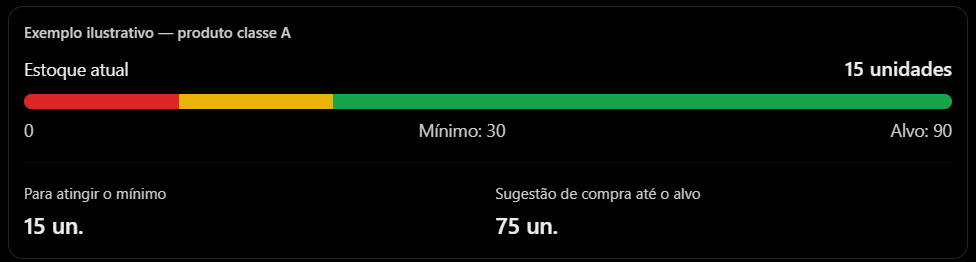

Essa distinção é importante: atingir o estoque mínimo resolve o déficit imediato em relação ao limite, enquanto atingir o estoque-alvo cria uma reserva maior para o próximo ciclo de abastecimento.

### Analisando os produtos críticos por classe

Agora vamos cruzar a classificação ABC com a situação do estoque.

In [449]:
# Quantidade de produtos por classe e status
resumo_estoque_abc = pd.crosstab(
    fato_estoque_v2["Classe_ABC"],
    fato_estoque_v2["Status_Estoque"]
)

display(resumo_estoque_abc)

# Calcular indicadores gerais
print(
    "Produtos críticos:",
    (fato_estoque_v2["Status_Estoque"]
     != "Estoque adequado").sum()
)

print(
    "Unidades para atingir o mínimo:",
    fato_estoque_v2["Necessidade_Reposicao"].sum()
)

print(
    "Sugestão total de compra:",
    fato_estoque_v2["Sugestao_Compra"].sum()
)

Status_Estoque,Abaixo do mínimo,Estoque adequado,Sem estoque
Classe_ABC,,,
A,61,359,1
B,45,451,4
C,41,926,5


Produtos críticos: 157
Unidades para atingir o mínimo: 1766
Sugestão total de compra: 8366


Essa análise permitirá identificar quantos produtos de classe A estão abaixo do mínimo e quantas unidades seriam necessárias para atingir os estoques-alvo definidos na simulação.

### Validando a nova versão

In [451]:
assert len(fato_estoque_v2) == len(dim_produtos)

assert fato_estoque_v2["SK_Produto"].is_unique

assert fato_estoque_v2["Classe_ABC"].notna().all()

assert (
    fato_estoque_v2["Estoque_Minimo"]
    <= fato_estoque_v2["Estoque_Alvo"]
).all()

assert (
    fato_estoque_v2["Necessidade_Reposicao"] >= 0
).all()

assert (
    fato_estoque_v2["Sugestao_Compra"] >= 0
).all()

print("Estoque V2 validado com sucesso!")

Estoque V2 validado com sucesso!


### Análise do estoque V2

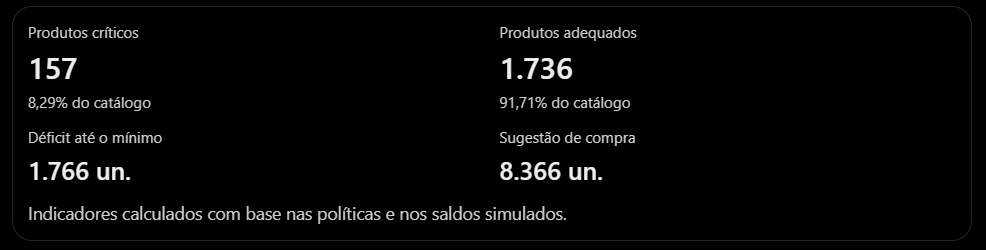

#### Produtos críticos por classe ABC

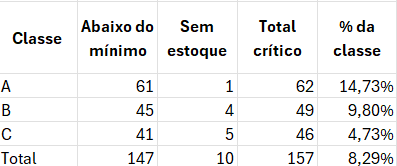

#### Produtos críticos por classe ABC

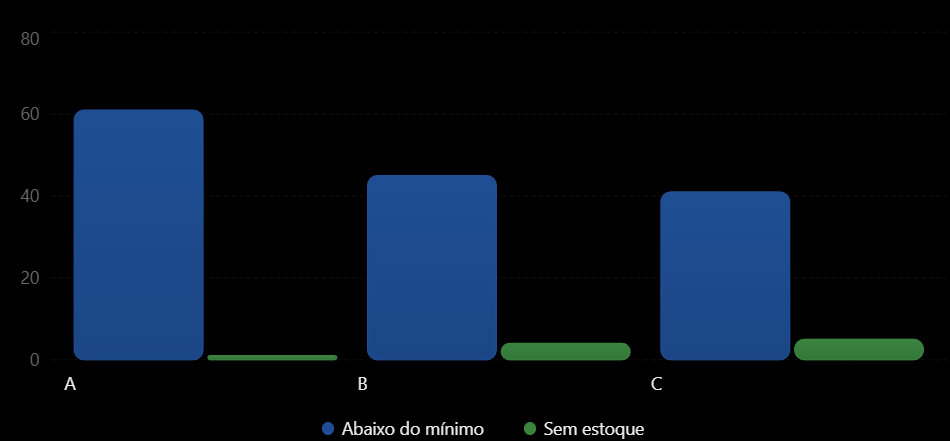

#### Principal descoberta

Dos 157 produtos críticos, 62 pertencem à classe A, que concentra aproximadamente 80% do faturamento histórico.

Esse será um indicador importante para o dashboard: produtos comercialmente relevantes com necessidade de reposição.

Vale observar que essa concentração também reflete a política simulada: foi estabelecido um estoque mínimo maior para os produtos A. Portanto, não é possível concluir que eles apresentam maior risco real de ruptura.

## 6.5 Atualizando Custos de Estoque Simulado com Base na Curva ABC

### Simulando custos mais coerentes

Na primeira versão, custos aleatórios entre 5 e 500 para todos os produtos foram atribuídos, independentemente do seu perfil.

Isso gerou um valor total de estoque muito elevado e pouco relacionado às características comerciais.

Essa premissa será aprimorada utilizando o valor médio por linha de venda de cada produto como referência.

Atenção: como as quantidades vendidas não são conhecidas, esse valor não é um preço unitário real. Será apenas uma referência sintética para gerar custos ilustrativos.

### Calculando a referência comercial

In [455]:
# Calcular valor médio por linha de venda
referencia_comercial = (
    fato_vendas_final
    .groupby("SK_Produto")
    .agg(
        Faturamento_Total=("Valor_Venda", "sum"),
        Linhas_Venda=("ID_Linha", "count")
    )
    .reset_index()
)

referencia_comercial["Valor_Medio_Linha"] = (
    referencia_comercial["Faturamento_Total"]
    / referencia_comercial["Linhas_Venda"]
)

display(referencia_comercial.head())

,SK_Produto,Faturamento_Total,Linhas_Venda,Valor_Medio_Linha
0,1,825.174,1,825.174000
1,2,1064.624,3,354.874667
2,3,2154.348,5,430.869600
3,4,723.842,6,120.640333
4,5,851.760,2,425.880000


Esse indicador será utilizado exclusivamente para construir nossa simulação.

### Criando um custo sintético

Será adotado um fator de custo entre 40% e 70% do valor médio por linha de venda.

Esses percentuais são hipóteses do projeto, não margens observadas na base.

In [457]:
# Criar uma nova versão para preservar a V2
fato_estoque_v3 = fato_estoque_v2.drop(
    columns=["Custo_Unitario", "Valor_Estoque"]
).copy()

# Adicionar referência comercial
fato_estoque_v3 = fato_estoque_v3.merge(
    referencia_comercial[
        ["SK_Produto", "Valor_Medio_Linha"]
    ],
    on="SK_Produto",
    how="left",
    validate="one_to_one"
)

# Gerador reproduzível
rng_custos = np.random.default_rng(seed=123)

# Fator de custo simulado
fato_estoque_v3["Fator_Custo"] = rng_custos.uniform(
    low=0.40,
    high=0.70,
    size=len(fato_estoque_v3)
)

# Custo sintético por unidade
fato_estoque_v3["Custo_Unitario"] = (
    fato_estoque_v3["Valor_Medio_Linha"]
    * fato_estoque_v3["Fator_Custo"]
).round(2)

display(
    fato_estoque_v3[
        [
            "SK_Produto",
            "Classe_ABC",
            "Valor_Medio_Linha",
            "Fator_Custo",
            "Custo_Unitario"
        ]
    ].head()
)

,SK_Produto,Classe_ABC,Valor_Medio_Linha,Fator_Custo,Custo_Unitario
0,1,B,825.174000,0.604706,498.99
1,2,B,354.874667,0.416146,147.68
2,3,A,430.869600,0.466108,200.83
3,4,B,120.640333,0.455312,54.93
4,5,B,425.880000,0.452772,192.83


A vantagem dessa abordagem é que produtos com valores comerciais diferentes também terão custos simulados diferentes.

Entretanto, isso não garante que o valor de estoque fique realista. Como a base não informa unidades vendidas, uma hipótese simplificada por enquanto será adotada.

### Calculando o valor do estoque e da reposição

In [459]:
# Valor do estoque atual
fato_estoque_v3["Valor_Estoque"] = (
    fato_estoque_v3["Estoque_Atual"]
    * fato_estoque_v3["Custo_Unitario"]
).round(2)

# Custo para atingir o estoque mínimo
fato_estoque_v3["Custo_Reposicao_Minima"] = (
    fato_estoque_v3["Necessidade_Reposicao"]
    * fato_estoque_v3["Custo_Unitario"]
).round(2)

# Custo para atingir o estoque-alvo
fato_estoque_v3["Custo_Compra_Sugerida"] = (
    fato_estoque_v3["Sugestao_Compra"]
    * fato_estoque_v3["Custo_Unitario"]
).round(2)

print(
    "Valor do estoque:",
    round(fato_estoque_v3["Valor_Estoque"].sum(), 2)
)

print(
    "Custo da reposição mínima:",
    round(fato_estoque_v3["Custo_Reposicao_Minima"].sum(), 2)
)

print(
    "Custo da compra sugerida:",
    round(fato_estoque_v3["Custo_Compra_Sugerida"].sum(), 2)
)

Valor do estoque: 28302830.37
Custo da reposição mínima: 402522.43
Custo da compra sugerida: 1993248.63


Esses indicadores representarão valores monetários simulados, sem conversão cambial.

### Análise financeira do estoque V3

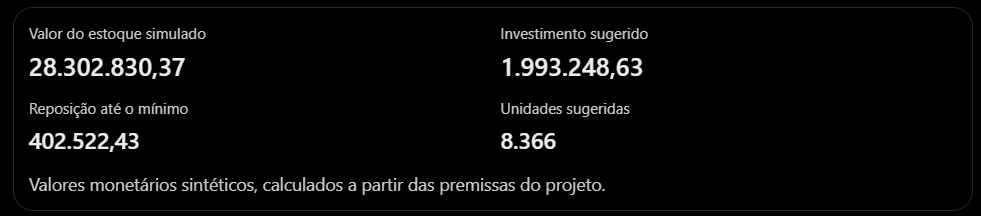

### Investimento sugerido por classe ABC

#### Distribuição do investimento sugerido

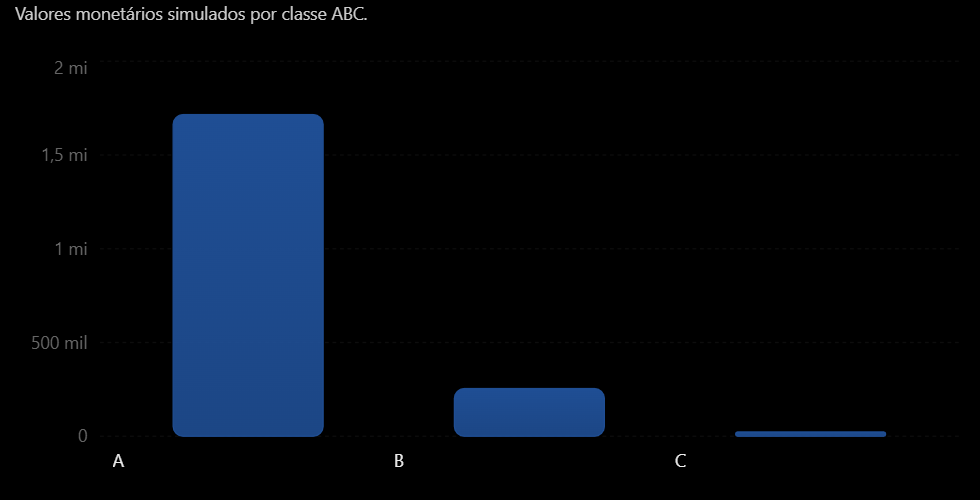

Principal descoberta

A classe A representa aproximadamente 86,1% do investimento sugerido, mesmo contendo apenas 22,24% dos produtos.

Isso acontece devido as combinações de custos sintéticos mais elevados com uma política de estoque-alvo maior para essa classe.

É um resultado útil para demonstrar análises financeiras no dashboard, mas é preciso manter clara essa limitação: os custos foram estimados a partir do valor médio por linha de venda, e não de preços reais de aquisição.

Além disso, o valor do estoque continua muito elevado em relação ao faturamento histórico.

### Calculando o investimento por classe ABC

Essa análise permitirá identificar quanto precisaríamos investir em cada classe para executar as compras sugeridas.

In [461]:
resumo_financeiro_abc = (
    fato_estoque_v3
    .groupby("Classe_ABC")
    .agg(
        Produtos=("SK_Produto", "count"),
        Valor_Estoque=("Valor_Estoque", "sum"),
        Unidades_Compra=("Sugestao_Compra", "sum"),
        Investimento_Compra=("Custo_Compra_Sugerida", "sum")
    )
    .reset_index()
)

display(resumo_financeiro_abc)

,Classe_ABC,Produtos,Valor_Estoque,Unidades_Compra,Investimento_Compra
0,A,421,22316713.03,4661,1715651.90
1,B,500,4417165.44,2530,254542.63
2,C,972,1568951.90,1175,23054.10


### Validando os cálculos

In [463]:
# Conferir quantidade de produtos
assert len(fato_estoque_v3) == len(dim_produtos)

# Conferir unicidade das chaves
assert fato_estoque_v3["SK_Produto"].is_unique

# Conferir custos válidos
assert fato_estoque_v3["Custo_Unitario"].notna().all()
assert (fato_estoque_v3["Custo_Unitario"] >= 0).all()

# Conferir valores financeiros
assert (fato_estoque_v3["Valor_Estoque"] >= 0).all()
assert (fato_estoque_v3["Custo_Compra_Sugerida"] >= 0).all()

# Conferir quantidades de reposição
assert (
    fato_estoque_v3["Sugestao_Compra"].sum() == 8366
)

print("Estoque V3 validado com sucesso!")

Estoque V3 validado com sucesso!


In [464]:
resumo_financeiro_abc

,Classe_ABC,Produtos,Valor_Estoque,Unidades_Compra,Investimento_Compra
0,A,421,22316713.03,4661,1715651.90
1,B,500,4417165.44,2530,254542.63
2,C,972,1568951.90,1175,23054.10


## 6.6 Criando Data de Referência do Estoque

### Finalizando a Fato_Estoque

Uma decisão importante precisa ser tomada: qual será a granularidade da tabela?

Cada linha da Fato_Estoque representará a posição simulada de um produto em uma data de referência.

Como há apenas uma posição inicial, será utilizado 31/12/2018, data de encerramento do período histórico de vendas.

Essa data é uma referência fictícia da simulação, não um inventário efetivamente realizado naquele dia.

### Criando a data de referência

In [467]:
# Criar cópia para a tabela final
fato_estoque_final = fato_estoque_v3.copy()

# Definir data de referência simulada
data_referencia = pd.Timestamp("2018-12-31")

fato_estoque_final["Data_Referencia"] = (
    data_referencia
)

print(
    "Data de referência:",
    fato_estoque_final["Data_Referencia"].unique()
)

print(
    "Produtos:",
    len(fato_estoque_final)
)

Data de referência: <DatetimeArray>
['2018-12-31 00:00:00']
Length: 1, dtype: datetime64[s]
Produtos: 1893


A data poderá ser relacionada à Dim_Calendario no Power BI.

Entretanto, há um cuidado com a interpretação: como existe apenas uma fotografia do estoque, não é possível construir uma evolução histórica real dos saldos.

### Adicionando a origem dos dados

In [469]:
fato_estoque_final["Origem_Dados"] = (
    "Estoque simulado"
)

fato_estoque_final["Versao_Simulacao"] = (
    "V3 - Politica ABC e custo sintetico"
)

Esses campos serão úteis para documentar o projeto e evitar que os valores sejam confundidos com dados reais.

### Selecionando as colunas finais

Os campos auxiliares que não são necessários manter na tabela fato, serão removidos.

Também será retirado Classe_ABC, porque essa classificação será armazenada na Dim_Produtos.

Atualizando a dimensão:

In [471]:
# Adicionar classificação ABC à dimensão de produtos
dim_produtos_final = dim_produtos.merge(
    analise_abc[
        ["SK_Produto", "Classe_ABC"]
    ],
    on="SK_Produto",
    how="left",
    validate="one_to_one"
)

assert len(dim_produtos_final) == len(dim_produtos)
assert dim_produtos_final["Classe_ABC"].notna().all()

print("Dim_Produtos atualizada!")

Dim_Produtos atualizada!


In [472]:
colunas_estoque = [
    "SK_Produto",
    "Data_Referencia",
    "Estoque_Atual",
    "Estoque_Minimo",
    "Estoque_Alvo",
    "Custo_Unitario",
    "Valor_Estoque",
    "Status_Estoque",
    "Necessidade_Reposicao",
    "Sugestao_Compra",
    "Custo_Reposicao_Minima",
    "Custo_Compra_Sugerida",
    "Origem_Dados",
    "Versao_Simulacao"
]

fato_estoque_final = fato_estoque_final[
    colunas_estoque
].copy()

display(fato_estoque_final.head())

,SK_Produto,Data_Referencia,Estoque_Atual,Estoque_Minimo,Estoque_Alvo,Custo_Unitario,Valor_Estoque,Status_Estoque,Necessidade_Reposicao,Sugestao_Compra,Custo_Reposicao_Minima,Custo_Compra_Sugerida,Origem_Dados,Versao_Simulacao
0,1,2018-12-31,17,20,60,498.99,8482.83,Abaixo do mínimo,3,43,1496.97,21456.57,Estoque simulado,V3 - Politica ABC e custo sintetico
1,2,2018-12-31,155,20,60,147.68,22890.40,Estoque adequado,0,0,0.00,0.00,Estoque simulado,V3 - Politica ABC e custo sintetico
2,3,2018-12-31,131,30,90,200.83,26308.73,Estoque adequado,0,0,0.00,0.00,Estoque simulado,V3 - Politica ABC e custo sintetico
3,4,2018-12-31,88,20,60,54.93,4833.84,Estoque adequado,0,0,0.00,0.00,Estoque simulado,V3 - Politica ABC e custo sintetico
4,5,2018-12-31,87,20,60,192.83,16776.21,Estoque adequado,0,0,0.00,0.00,Estoque simulado,V3 - Politica ABC e custo sintetico


### Validando o modelo final

In [474]:
# Quantidade de registros
assert len(fato_estoque_final) == 1893

# Cada produto aparece uma única vez nesta fotografia
assert fato_estoque_final["SK_Produto"].is_unique

# Verificar correspondência com Dim_Produtos
assert fato_estoque_final["SK_Produto"].isin(
    dim_produtos_final["SK_Produto"]
).all()

# Verificar data no calendário
assert fato_estoque_final["Data_Referencia"].isin(
    dim_calendario["Data"]
).all()

# Verificar ausência de nulos
assert fato_estoque_final.isna().sum().sum() == 0

# Validar totais financeiros
assert np.isclose(
    fato_estoque_final["Valor_Estoque"].sum(),
    28302830.37
)

assert np.isclose(
    fato_estoque_final["Custo_Compra_Sugerida"].sum(),
    1993248.63
)

# Validar quantidades
assert (
    fato_estoque_final["Sugestao_Compra"].sum()
    == 8366
)

print("Fato_Estoque validada com sucesso!")

Fato_Estoque validada com sucesso!


### Como ficará nosso modelo estrela?

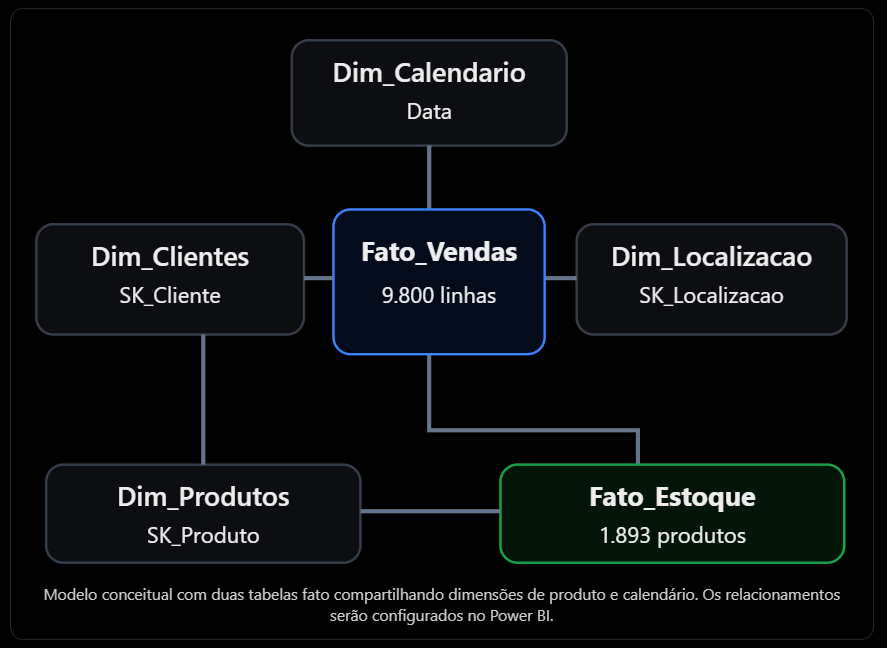

No Power BI, haverá duas tabelas fato com granularidades diferentes: vendas por item de pedido e estoque por produto na data de referência.

Não será criado um relacionamento direto entre as duas tabelas fato. A integração será realizada por meio das dimensões compartilhadas.

## 6.7 Exportando o Modelo Completo

### Exportando o modelo completo

O modelo agora possui seis tabelas:

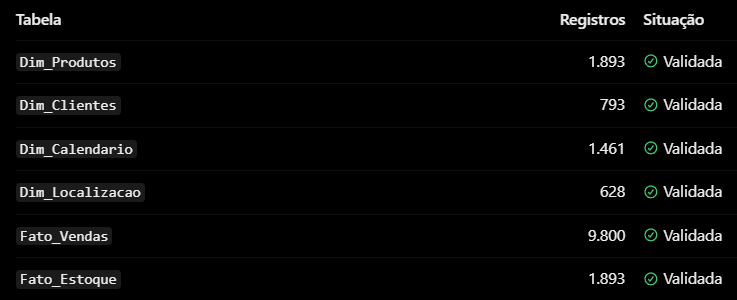

### Exportando as seis tabelas

In [478]:
# Pasta de destino
pasta_modelo = Path("../dados_tratados/modelo_estrela")

pasta_modelo.mkdir(
    parents=True,
    exist_ok=True
)

# Tabelas finais
tabelas_finais = {
    "Dim_Produtos": dim_produtos_final,
    "Dim_Clientes": dim_clientes,
    "Dim_Calendario": dim_calendario,
    "Dim_Localizacao": dim_localizacao,
    "Fato_Vendas": fato_vendas_final,
    "Fato_Estoque": fato_estoque_final
}

# Exportar os arquivos
for nome, tabela in tabelas_finais.items():

    caminho = pasta_modelo / f"{nome}.csv"

    tabela.to_csv(
        caminho,
        sep=";",
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d",
        float_format="%.4f"
    )

    print(
        f"{nome}: {len(tabela)} registros exportados"
    )

print("Exportação concluída!")

Dim_Produtos: 1893 registros exportados
Dim_Clientes: 793 registros exportados
Dim_Calendario: 1461 registros exportados
Dim_Localizacao: 628 registros exportados
Fato_Vendas: 9800 registros exportados
Fato_Estoque: 1893 registros exportados
Exportação concluída!


Esse código substituirá os arquivos anteriores de mesmo nome, incluindo a Dim_Produtos atualizada com a classificação ABC.

### Conferindo os arquivos exportados

Validando se os arquivos podem ser lidos corretamente.

In [480]:
# Ler novamente os arquivos exportados
for nome, tabela_original in tabelas_finais.items():

    caminho = pasta_modelo / f"{nome}.csv"

    tabela_importada = pd.read_csv(
        caminho,
        sep=";",
        encoding="utf-8-sig"
    )

    assert len(tabela_importada) == len(tabela_original)

    assert (
        len(tabela_importada.columns)
        == len(tabela_original.columns)
    )

    print(
        f"{nome}: arquivo conferido!"
    )

print("Todos os arquivos foram validados!")

Dim_Produtos: arquivo conferido!
Dim_Clientes: arquivo conferido!
Dim_Calendario: arquivo conferido!
Dim_Localizacao: arquivo conferido!
Fato_Vendas: arquivo conferido!
Fato_Estoque: arquivo conferido!
Todos os arquivos foram validados!


Esse teste confirma a quantidade de linhas e colunas. As validações financeiras e de relacionamentos já foram realizadas nos DataFrames originais; serão conferidas novamente após a importação no Power BI.